# Reproducibility notebook — CNN-assisted joint gateway assignment and routing for LoRa-based smart waste management

This notebook contains the **complete code** of the reproducibility package in one file. It:
1. writes the simulator, labeller, CNN, baselines and experiment scripts to disk (`%%writefile` cells);
2. runs the full pipeline: dataset → CNN training → paired evaluation → runtime → density → weight sensitivity → ablation → labeller check;
3. builds and displays every table and figure from the raw outputs.

**Scope.** The original experimental code and seeds were not retained. This is an independent, open re-implementation of the method described in the manuscript, extended with relay-routing decisions. All numbers shown here are produced by this code; nothing is copied from the submitted manuscript.

**Runtime.** About 45–60 min on a 2-core CPU (Google Colab CPU runtime is fine). If `outputs/` already exists, the pipeline is skipped and existing results are displayed; set `FORCE_RERUN = True` to regenerate everything.

In [1]:
# Setup. In Colab, uncomment the next line (PyTorch is already installed there).
# %pip install -q pyyaml tabulate
import os, sys, subprocess, time
WORK = os.path.abspath("lorasw_repro")
for d in ["config", "lorasw", "scripts"]:
    os.makedirs(os.path.join(WORK, d), exist_ok=True)
os.chdir(WORK)
FORCE_RERUN = False
RUN_PIPELINE = FORCE_RERUN or not os.path.exists("outputs/tables/table_main_results.md")
print("Working directory:", WORK, "| run pipeline:", RUN_PIPELINE)

Working directory: /content/lorasw_repro | run pipeline: True


## 1. Configuration
Every experiment reads this file. Change a value and rerun to regenerate all results.

In [2]:
%%writefile config/default.yaml
# Reproducibility configuration for
# "A CNN-Assisted Framework for Routing and Gateway Assignment in
#  LoRa-Based Smart Waste Management Networks"
#
# Every experiment reads this file. Change a value here, rerun run_all.sh,
# and every table and figure is regenerated from scratch.

seed: 20261011                  # master seed; all other seeds are derived from it

area_m: 1000                    # square deployment side L (m)
n_nodes: [200, 800]             # sensor-node range sampled per scenario
n_gateways: 4
gateway_xy: [[250, 250], [750, 250], [250, 750], [750, 750]]
n_sinks: 2
road_spacing_m: 100             # sinks are placed on a Manhattan road grid

radio:
  bandwidth_hz: 125000
  coding_rate: 1                # 4/5
  preamble_symbols: 8
  node_tx_dbm: 14               # EU868 end-device limit
  gateway_tx_dbm: 27            # 869.4-869.65 MHz sub-band (500 mW, 10 %)
  uplink_channels: 3            # 868.1 / 868.3 / 868.5 MHz
  pl0_db: 127.41                # log-distance model (Bor et al., 2016)
  d0_m: 40
  gamma: 2.08
  shadow_sigma_db: 3.57         # static per-link shadowing
  fading_sigma_db: 1.0          # per-packet variation
  measure_sigma_db: 2.0         # server-side RSSI measurement noise
  join_sigma_db: 4.0            # one-shot RSSI used at join (conventional baseline)
  gw_sink_pl_bonus_db: 10.0     # elevated gateway mast for gateway->sink link
  adr_margin_db: 5.0
  sink_link_margin_db: 6.0
  capture_db: 6.0
  gateway_demodulators: 8
  node_duty_cycle: 0.01
  gateway_duty_cycle: 0.10
  gateway_bucket_s: 36.0        # token-bucket depth for gateway duty cycle

energy:
  p_tx_w: 0.145                 # SX1276 @14 dBm, 3.3 V
  p_rx_w: 0.0363                # SX1276 RX, 3.3 V
  relay_listen_duty: 0.01       # CAD-based listening of relays / cluster heads
  e_min: 0.2                    # residual-energy fraction required for relay/CH roles

traffic:
  payload_bytes: 20
  frame_overhead_bytes: 13
  rate_per_hour: [2, 12]        # per-node reporting rate range
  urgent_fill: 0.8              # bins at or above this fill send confirmed uplinks
  max_attempts: 3
  ack_timeout_s: 3.0
  backoff_s: [1.0, 3.0]
  sim_time_s: 3600
  drain_time_s: 600

baselines:
  leach_ch_fraction: 0.05
  leach_agg_period_s: 60
  relay_min_sf: 11              # nodes at this SF or above look for a relay
  relay_max_sf: 9               # relay candidates must be at this SF or below

optimizer:
  weights: [0.5, 0.3, 0.2]      # w1 (PDR), w2 (energy), w3 (delay) -- SET TO THE VALUES USED IN THE PAPER
  lambdas: [0.0, 0.5, 2.0]      # load-balancing strengths in the candidate set
  relay_thresholds: [13, 12, 11, 10]   # relay nodes at SF >= threshold; 13 = no relaying
  priority_weighting: true      # PDR term weighted by (1 + fill level)

cnn:
  grid: 32
  channels: [rssi, energy, density, traffic_mobility, fill]
  epochs: 100
  patience: 15
  batch_size: 64
  lr: 0.001
  dropout: 0.5
  val_fraction: 0.2

dataset:
  n_samples: 5000

evaluation:
  n_runs: 20
  methods: [conventional, rssi, leach, relay, cnn, exhaustive]

runtime:
  n_states: 100

sensitivity:
  w1_values: [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
  n_runs: 10
  n_nodes: 500
  n_train: 2500

density:
  n_values: [200, 300, 400, 500, 600, 700, 800]
  n_runs: 10

ablation:
  n_runs: 10

Writing config/default.yaml


## 2. Simulator, decision space, labeller and CNN (`lorasw` package)

### `lorasw/__init__.py` — Package marker

In [3]:
%%writefile lorasw/__init__.py
"""lorasw: LoRa smart-waste reproducibility package."""

Writing lorasw/__init__.py


### `lorasw/radio.py` — LoRa PHY: sensitivity, time-on-air, path loss, ADR

In [4]:
%%writefile lorasw/radio.py
"""LoRa physical-layer helpers: sensitivity, time-on-air, path loss, ADR."""
import math
import numpy as np

SFS = np.array([7, 8, 9, 10, 11, 12])
# SX1276 sensitivity at 125 kHz (dBm), indexed by SF
SENS = {7: -123.0, 8: -126.0, 9: -129.0, 10: -132.0, 11: -134.5, 12: -137.0}
SENS_ARR = np.array([SENS[s] for s in SFS])
# EU868 maximum MACPayload per data rate (bytes)
MAX_PAYLOAD = {7: 250, 8: 250, 9: 123, 10: 59, 11: 59, 12: 59}


def toa(sf, payload_bytes, bw=125e3, cr=1, preamble=8, header=True, crc=True):
    """LoRa time-on-air in seconds (Semtech AN1200.13)."""
    ts = (2 ** sf) / bw
    de = 1 if (sf >= 11 and bw == 125e3) else 0
    h = 0 if header else 1
    num = 8 * payload_bytes - 4 * sf + 28 + 16 * int(crc) - 20 * h
    n_payload = 8 + max(math.ceil(num / (4 * (sf - 2 * de))) * (cr + 4), 0)
    return (preamble + 4.25) * ts + n_payload * ts


def path_loss(d, pl0, d0, gamma):
    d = np.maximum(d, 1.0)
    return pl0 + 10.0 * gamma * np.log10(d / d0)


def min_sf(rssi, margin):
    """Smallest SF whose sensitivity + margin is met; 0 where no SF works."""
    rssi = np.asarray(rssi, dtype=float)
    out = np.zeros(rssi.shape, dtype=int)
    for sf in SFS[::-1]:
        out = np.where(rssi >= SENS[sf] + margin, sf, out)
    return out


def batch_capacity(sf, payload, overhead):
    return max(1, (MAX_PAYLOAD[int(sf)] - overhead) // payload)

Writing lorasw/radio.py


### `lorasw/scenario.py` — Random deployments (true vs measured channel)

In [5]:
%%writefile lorasw/scenario.py
"""Random smart-waste deployment scenarios.

A scenario holds the *true* channel (used only by the packet simulator) and the
*measured* channel (what a LoRaWAN network server sees, used by every decision
method). Keeping the two apart stops any method from seeing ground truth.
"""
import numpy as np
from .radio import path_loss, min_sf


def generate(rng, cfg, n_nodes=None):
    r = cfg["radio"]
    L = cfg["area_m"]
    if n_nodes is None:
        lo, hi = cfg["n_nodes"]
        n_nodes = int(rng.integers(lo, hi + 1))
    N, G, K = n_nodes, cfg["n_gateways"], cfg["n_sinks"]

    node_xy = rng.uniform(0, L, size=(N, 2))
    gw_xy = np.asarray(cfg["gateway_xy"], dtype=float)
    # sinks sit on a road (one coordinate on the road grid)
    sp = cfg["road_spacing_m"]
    roads = np.arange(0, L + 1, sp)
    sink_xy = np.empty((K, 2))
    for k in range(K):
        if rng.random() < 0.5:
            sink_xy[k] = [rng.choice(roads), rng.uniform(0, L)]
        else:
            sink_xy[k] = [rng.uniform(0, L), rng.choice(roads)]
    # canonical order (west to east) so that sink indices in the labels are identifiable
    sink_xy = sink_xy[np.lexsort((sink_xy[:, 1], sink_xy[:, 0]))]

    d_ng = np.linalg.norm(node_xy[:, None, :] - gw_xy[None, :, :], axis=2)
    d_nn = np.linalg.norm(node_xy[:, None, :] - node_xy[None, :, :], axis=2)
    d_gs = np.linalg.norm(gw_xy[:, None, :] - sink_xy[None, :, :], axis=2)

    sh_ng = rng.normal(0, r["shadow_sigma_db"], size=(N, G))
    sh_nn = rng.normal(0, r["shadow_sigma_db"], size=(N, N))
    sh_nn = np.triu(sh_nn, 1); sh_nn = sh_nn + sh_nn.T          # reciprocal links
    sh_gs = rng.normal(0, r["shadow_sigma_db"], size=(G, K))

    pl = lambda d: path_loss(d, r["pl0_db"], r["d0_m"], r["gamma"])
    true_ng = r["node_tx_dbm"] - pl(d_ng) - sh_ng
    true_nn = r["node_tx_dbm"] - pl(d_nn) - sh_nn
    np.fill_diagonal(true_nn, -np.inf)
    true_gs = r["gateway_tx_dbm"] - (pl(d_gs) - r["gw_sink_pl_bonus_db"]) - sh_gs

    meas_ng = true_ng + rng.normal(0, r["measure_sigma_db"], size=(N, G))
    meas_nn = true_nn + rng.normal(0, r["measure_sigma_db"], size=(N, N))
    meas_gs = true_gs + rng.normal(0, r["measure_sigma_db"], size=(G, K))
    join_ng = true_ng + rng.normal(0, r["join_sigma_db"], size=(N, G))

    t = cfg["traffic"]
    energy = rng.uniform(0.1, 1.0, size=N)                 # residual-energy fraction
    fill = rng.uniform(0.0, 1.0, size=N)                   # waste fill level
    rate = rng.uniform(*t["rate_per_hour"], size=N)        # packets per hour
    urgent = fill >= t["urgent_fill"]

    # Standard ADR: SF set from the best measured gateway link.
    best = meas_ng.max(axis=1)
    sf = min_sf(best, r["adr_margin_db"])
    sf = np.where((sf == 0) & (best >= -137.0), 12, sf)     # SF12 without margin
    covered = sf > 0

    return dict(
        N=N, G=G, K=K, node_xy=node_xy, gw_xy=gw_xy, sink_xy=sink_xy,
        true_ng=true_ng, true_nn=true_nn, true_gs=true_gs,
        meas_ng=meas_ng, meas_nn=meas_nn, meas_gs=meas_gs, join_ng=join_ng,
        energy=energy, fill=fill, rate=rate, urgent=urgent, sf=sf, covered=covered,
    )

Writing lorasw/scenario.py


### `lorasw/plans.py` — Decision space (192 configurations), analytic labeller, routing plans and baselines

In [6]:
%%writefile lorasw/plans.py
"""Decision space, analytic labeller and routing plans.

Candidate configurations (joint gateway assignment and routing)
----------------------------------------------------------------
A configuration q = (sink map, lambda, relay threshold):
  * sink map        : which mobile sink serves each gateway (K**G = 16 options)
  * lambda          : load-balancing strength of the server-side gateway
                      assignment rule (each uplink transmitter -> exactly one gateway)
  * relay threshold : nodes whose ADR spreading factor is >= threshold send through
                      a one-hop relay (a neighbour at SF <= 9 with enough residual
                      energy); threshold 13 means "no relaying"
Q = 16 x |lambdas| x |relay thresholds| classes (192 with the default config).

The exhaustive labeller evaluates every configuration with the analytic model in
`analytic_eval` and stores all metric vectors, so labels for any objective
weights can be recomputed without re-simulation.

A *plan* is what the packet simulator executes: first-hop receiver and SF for every
node, the relays and the gateway each relay forwards to, and the gateway->sink map.
"""
import itertools
import numpy as np
from .radio import SENS, toa, min_sf, batch_capacity

NO_RELAY = 13


# ---------------------------------------------------------------- decision space
def candidate_configs(cfg):
    G, K = cfg["n_gateways"], cfg["n_sinks"]
    maps = list(itertools.product(range(K), repeat=G))
    thr = cfg["optimizer"].get("relay_thresholds", [NO_RELAY])
    return [(m, lam, th) for th in thr for lam in cfg["optimizer"]["lambdas"] for m in maps]


def sink_sf(scn, cfg):
    return min_sf(scn["meas_gs"], cfg["radio"]["sink_link_margin_db"])  # (G, K), 0 = infeasible


# ---------------------------------------------------------------- precompute
def _relay_choice(scn, cfg):
    """For every node: best relay candidate (max residual energy) and link SF; -1 if none."""
    r, e = cfg["radio"], cfg["energy"]
    N = scn["N"]; sf = scn["sf"]
    max_sf = cfg["baselines"]["relay_max_sf"]
    cand = np.where(scn["covered"] & (sf <= max_sf) & (scn["energy"] >= e["e_min"]))[0]
    relay_of = np.full(N, -1); link_sf = np.zeros(N, dtype=int)
    if len(cand) == 0:
        return relay_of, link_sf
    need = np.where(scn["covered"] & (sf >= 10))[0]
    for i in need:
        lsf = min_sf(scn["meas_nn"][i, cand], r["adr_margin_db"])
        good = np.where((lsf > 0) & (lsf <= max_sf))[0]
        if len(good):
            k = good[np.argmax(scn["energy"][cand[good]])]
            relay_of[i] = cand[k]; link_sf[i] = max(7, int(lsf[k]))
    return relay_of, link_sf


def _p_ok(rx_rssi, tx_sf, tx_load, targets, capture):
    """Pure-ALOHA success probability at one receiver for each target transmitter.

    rx_rssi : (N,) measured RSSI of every transmitter at this receiver
    tx_sf, tx_load : per-transmitter SF and per-channel offered load
    """
    out = np.zeros(len(targets))
    for s in np.unique(tx_sf[targets]):
        grp = np.where(tx_sf == s)[0]
        rs = rx_rssi[grp]; order = np.argsort(rs)
        rs_sorted = rs[order]; csum = np.concatenate([[0.0], np.cumsum(tx_load[grp][order])])
        sel = np.where(tx_sf[targets] == s)[0]
        tr = targets[sel]
        lo = np.searchsorted(rs_sorted, rx_rssi[tr] - capture, side="left")
        interf = csum[-1] - csum[lo] - tx_load[tr]
        out[sel] = np.exp(-2.0 * np.maximum(interf, 0.0))
    return out


def mode_state(scn, pre, cfg, th):
    """Transmitter roles, SFs, loads and collision probabilities for relay threshold th."""
    key = ("mode", th)
    if key in pre:
        return pre[key]
    r, t = cfg["radio"], cfg["traffic"]
    N, G = scn["N"], scn["G"]
    sf = scn["sf"]; cov = scn["covered"]
    pl = t["frame_overhead_bytes"] + t["payload_bytes"]
    member = cov & (sf >= th) & (pre["relay_of"] >= 0)
    relay_of = np.where(member, pre["relay_of"], -1)
    relays = np.unique(relay_of[relay_of >= 0])
    member = member & ~np.isin(np.arange(N), relays)          # a relay never uses a relay itself
    relay_of = np.where(member, relay_of, -1)
    relays = np.unique(relay_of[relay_of >= 0])

    tx_sf = np.where(member, pre["link_sf"], sf)
    rate = scn["rate"] / 3600.0
    fwd_rate = np.zeros(N)
    np.add.at(fwd_rate, relay_of[member], rate[member])
    toa_tx = np.array([toa(s, pl) if s > 0 else 0.0 for s in tx_sf])
    load = (rate + fwd_rate) * toa_tx / r["uplink_channels"]
    load[~cov] = 0.0

    uplink = np.where(cov & ~member)[0]                        # transmitters to gateways
    p_gw = np.zeros((N, G))
    for j in range(G):
        p_gw[uplink, j] = _p_ok(scn["meas_ng"][:, j], tx_sf, load, uplink, r["capture_db"])
    p_mem = np.zeros(N)
    for rl in relays:
        mem = np.where(relay_of == rl)[0]
        rr = scn["meas_nn"][:, rl].copy(); rr[rl] = -np.inf
        rr = np.where(cov, rr, -np.inf)
        p_mem[mem] = _p_ok(rr, tx_sf, load, mem, r["capture_db"])
    st = dict(member=member, relay_of=relay_of, relays=relays, tx_sf=tx_sf, toa_tx=toa_tx,
              fwd_rate=fwd_rate, p_gw=p_gw, p_mem=p_mem, uplink=uplink)
    pre[key] = st
    return st


def precompute(scn, cfg):
    """Decision-independent quantities (server-side, measured data only)."""
    t = cfg["traffic"]
    pl = t["frame_overhead_bytes"] + t["payload_bytes"]
    sf = scn["sf"]
    toa_node = np.array([toa(s, pl) if s > 0 else 0.0 for s in sf])
    sens_node = np.array([SENS[s] if s > 0 else 0.0 for s in sf])
    margin = scn["meas_ng"] - sens_node[:, None]
    feasible = (margin >= 0) & scn["covered"][:, None]
    relay_of, link_sf = _relay_choice(scn, cfg)
    return dict(toa_node=toa_node, margin=margin, feasible=feasible, sf_gs=sink_sf(scn, cfg),
                relay_of=relay_of, link_sf=link_sf)


# ---------------------------------------------------------------- assignment rule
def _fwd_airtime_per_packet(sf_f, cfg):
    t = cfg["traffic"]
    if sf_f == 0:
        return np.inf
    B = batch_capacity(sf_f, t["payload_bytes"], t["frame_overhead_bytes"])
    return toa(sf_f, t["frame_overhead_bytes"] + t["payload_bytes"] * B) / B


def assign(scn, pre, cfg, sink_map, lam, st):
    """Priority-ordered greedy gateway assignment for uplink transmitters (-1 = none)."""
    N, G = scn["N"], scn["G"]
    a_fwd = [_fwd_airtime_per_packet(pre["sf_gs"][j, sink_map[j]], cfg) for j in range(G)]
    base = pre["margin"] + 10.0 * np.log10(np.maximum(st["p_gw"], 1e-6))
    elig = np.zeros(N, bool); elig[st["uplink"]] = True
    base = np.where(pre["feasible"] & elig[:, None], base, -np.inf)
    out = np.full(N, -1, dtype=int)
    ok = np.isfinite(base).any(axis=1)
    if lam == 0:
        out[ok] = np.argmax(base[ok], axis=1)
        return out
    rate = (scn["rate"] / 3600.0 + st["fwd_rate"]).tolist()
    order = np.argsort(-scn["fill"])
    load = [0.0] * G
    base_l = base.tolist()
    for i in order:
        if not ok[i]:
            continue
        row = base_l[i]; best, bj = -np.inf, -1
        for j in range(G):
            if row[j] == -np.inf:
                continue
            s = row[j] - lam * 100.0 * load[j]
            if s > best:
                best, bj = s, j
        out[i] = bj
        load[bj] += rate[i] * (a_fwd[bj] if np.isfinite(a_fwd[bj]) else 0.0)
    return out


# ---------------------------------------------------------------- analytic model
def analytic_eval(scn, pre, cfg, q):
    """Expected PDR, energy and delay of configuration q (used for labelling)."""
    sink_map, lam, th = candidate_configs(cfg)[q]
    r, t, e = cfg["radio"], cfg["traffic"], cfg["energy"]
    G, K, N = scn["G"], scn["K"], scn["N"]
    T = t["sim_time_s"]; D = t["drain_time_s"]; R = t["max_attempts"]
    dc = r["gateway_duty_cycle"]; ndc = r["node_duty_cycle"]
    OH, PL = t["frame_overhead_bytes"], t["payload_bytes"]
    sf_f = np.array([pre["sf_gs"][j, sink_map[j]] for j in range(G)])
    if np.any(sf_f == 0):
        return None
    st = mode_state(scn, pre, cfg, th)
    a = assign(scn, pre, cfg, sink_map, lam, st)
    rate = scn["rate"] / 3600.0
    urgent = scn["urgent"]; cov = scn["covered"]
    member, relay_of = st["member"], st["relay_of"]
    toa_ack = toa(9, OH); toa_ack_n = toa(7, OH)
    retx_wait = t["ack_timeout_s"] + np.mean(t["backoff_s"])

    up = np.where(a >= 0)[0]
    tot_rate = rate + st["fwd_rate"]
    urg_rate = rate * urgent
    urg_fwd = np.zeros(N); np.add.at(urg_fwd, relay_of[member], urg_rate[member])
    lam_j = np.bincount(a[up], weights=tot_rate[up], minlength=G)
    ack_j = np.bincount(a[up], weights=(urg_rate + urg_fwd)[up], minlength=G)
    B_max = np.array([batch_capacity(s, PL, OH) for s in sf_f])
    T_full = np.array([toa(s, OH + PL * b) for s, b in zip(sf_f, B_max)])
    B_eff = np.clip(lam_j * T_full / dc, 1, B_max)
    T_f = np.array([toa(s, OH + int(round(PL * b))) for s, b in zip(sf_f, B_eff)])
    f_j = lam_j / B_eff
    u_j = f_j * T_f + ack_j * toa_ack
    deaf = np.minimum(u_j, 0.95)
    frac = np.minimum(1.0, (dc * (T + D) + r["gateway_bucket_s"]) / np.maximum(u_j * T, 1e-9))

    # relay radio: own + forwarded frames under the 1 % node duty cycle
    toa_tx = st["toa_tx"]
    rho_r = tot_rate * toa_tx / ndc
    W_r = np.where(rho_r < 1, rho_r * (toa_tx / ndc) / (2 * np.maximum(1 - rho_r, 1e-6)),
                   (1 - 1 / np.maximum(rho_r, 1e-9)) * T / 2)   # served packets of an overloaded queue
    fr_r = np.minimum(1.0, 1.0 / np.maximum(rho_r, 1e-9))
    u_r = np.minimum(tot_rate * toa_tx + urg_fwd * toa_ack_n, 0.95)

    def hop(p, u):
        return np.where(u, 1 - (1 - p) ** R, p)

    def attempts(s, u):
        return np.where(u, sum((1 - s) ** k for k in range(R)), 1.0)

    deliv = np.zeros(N); att1 = np.ones(N); att2 = np.ones(N)
    D_i = np.zeros(N)
    # gateway forwarding delay
    rho_g = f_j * T_f / dc
    W_g = np.where(rho_g < 1, rho_g * (T_f / dc) / (2 * np.maximum(1 - rho_g, 1e-6)),
                   (1 - 1 / np.maximum(rho_g, 1e-9)) * T / 2)
    W_b = (B_eff - 1) / (2 * np.maximum(lam_j, 1e-9))
    rho_s = np.zeros(K)
    for j in range(G):
        rho_s[sink_map[j]] += f_j[j] * T_f[j]
    W_s = np.array([rho_s[k] * T_f.mean() / (2 * max(1 - rho_s[k], 1e-3)) for k in range(K)])
    D_fwd = W_g + W_b + T_f + np.array([W_s[sink_map[j]] for j in range(G)])

    # uplink transmitters (direct nodes and relays' own packets)
    j = a[up]
    p_up = st["p_gw"][up, j] * (1 - deaf[j])
    deliv[up] = hop(p_up, urgent[up]) * frac[j] * fr_r[up]
    att1[up] = attempts(p_up * (1 - deaf[j]), urgent[up])
    D_i[up] = toa_tx[up] + np.where(urgent[up], (att1[up] - 1) * (retx_wait + toa_tx[up]), 0) + W_r[up] * (st["fwd_rate"][up] > 0) + D_fwd[j]
    # relay members
    mem = np.where(member)[0]
    if len(mem):
        rl = relay_of[mem]; jr = a[rl]
        okr = jr >= 0
        p1 = st["p_mem"][mem] * (1 - u_r[rl])
        p2 = np.where(okr, st["p_gw"][rl, np.maximum(jr, 0)] * (1 - deaf[np.maximum(jr, 0)]), 0.0)
        deliv[mem] = hop(p1, urgent[mem]) * hop(p2, urgent[mem]) * fr_r[rl] * np.where(okr, frac[np.maximum(jr, 0)], 0)
        att1[mem] = attempts(p1 * (1 - u_r[rl]), urgent[mem])
        att2[mem] = attempts(p2, urgent[mem])
        D_i[mem] = (toa_tx[mem] + np.where(urgent[mem], (att1[mem] - 1) * (retx_wait + toa_tx[mem]), 0)
                    + W_r[rl] + toa_tx[rl] + np.where(urgent[mem], (att2[mem] - 1) * (retx_wait + toa_tx[rl]), 0)
                    + np.where(okr, D_fwd[np.maximum(jr, 0)], 0))
    # uncovered or unassigned nodes deliver nothing
    unassigned = cov & ~member & (a < 0)
    att1[unassigned] = np.where(urgent[unassigned], R, 1)

    w = 1 + scn["fill"] if cfg["optimizer"]["priority_weighting"] else np.ones(N)
    wpdr = float((w * deliv).sum() / w.sum()); pdr = float(deliv.mean())

    # energy over the simulated hour (+ drain) per covered node
    n_pk = scn["rate"] * T / 3600.0
    sym = (2.0 ** np.maximum(st["tx_sf"], 7)) / r["bandwidth_hz"]
    E = n_pk * att1 * toa_tx * e["p_tx_w"] + n_pk * att1 * 2 * 8 * sym * e["p_rx_w"]
    if len(mem):
        fwd_pk = n_pk[mem]
        np.add.at(E, rl, fwd_pk * att2[mem] * toa_tx[rl] * e["p_tx_w"]           # forwarding
                  + fwd_pk * att1[mem] * toa_tx[mem] * e["p_rx_w"])               # receiving members
        E[st["relays"]] += e["p_rx_w"] * e["relay_listen_duty"] * (T + D)
    E_avg = float(E[cov].mean())
    wd = deliv[cov]
    D_avg = float((wd * D_i[cov]).sum() / max(wd.sum(), 1e-9))
    return dict(wpdr=wpdr, pdr=pdr, energy=E_avg, delay=D_avg)


def evaluate_all(scn, cfg, pre=None):
    """Analytic metrics for every candidate configuration -> array (Q, 4)."""
    pre = pre or precompute(scn, cfg)
    Q = len(candidate_configs(cfg))
    out = np.full((Q, 4), np.nan)
    for q in range(Q):
        res = analytic_eval(scn, pre, cfg, q)
        if res is not None:
            out[q] = [res["wpdr"], res["pdr"], res["energy"], res["delay"]]
    return out, pre


def objective_values(M, weights):
    """Eq. (11) with each term min-max normalised over the feasible configurations of
    the scenario, so that the weights express relative importance on a common scale."""
    ok = ~np.isnan(M[:, 0])
    def mm(v):
        lo, hi = np.nanmin(v[ok]), np.nanmax(v[ok])
        return (v - lo) / (hi - lo) if hi > lo else np.zeros_like(v)
    w1, w2, w3 = weights
    obj = np.full(len(M), -np.inf)
    obj[ok] = (w1 * mm(M[:, 0]) - w2 * mm(M[:, 2]) - w3 * mm(M[:, 3]))[ok]
    return obj


def label_from_metrics(M, weights):
    obj = objective_values(M, weights)
    return int(np.argmax(obj)), obj


# ---------------------------------------------------------------- plans
def plan_from_config(scn, pre, cfg, q):
    sink_map, lam, th = candidate_configs(cfg)[q]
    st = mode_state(scn, pre, cfg, th)
    a = assign(scn, pre, cfg, sink_map, lam, st)
    G, N = scn["G"], scn["N"]
    relays = st["relays"]
    rid = {int(n): G + k for k, n in enumerate(relays)}
    hop1 = a.copy(); hop1_sf = scn["sf"].copy()
    for i in np.where(st["member"])[0]:
        hop1[i] = rid[int(st["relay_of"][i])]; hop1_sf[i] = st["tx_sf"][i]
    return dict(hop1=hop1, hop1_sf=hop1_sf, relays=relays, relay_kind=["relay"] * len(relays),
                relay_gw=a[relays] if len(relays) else np.array([], int), sink_map=np.array(sink_map),
                gw_sf_sink=np.array([pre["sf_gs"][j, sink_map[j]] for j in range(G)]))


def _direct_plan(scn, gw, sink_map, sf_gs):
    G = scn["G"]
    return dict(hop1=gw.astype(int), hop1_sf=scn["sf"].copy(), relays=np.array([], int),
                relay_kind=[], relay_gw=np.array([], int), sink_map=np.array(sink_map),
                gw_sf_sink=np.array([sf_gs[j, sink_map[j]] for j in range(G)]))


def nearest_sink_map(scn, sf_gs):
    G = scn["G"]
    m = np.argmax(scn["meas_gs"], axis=1)
    for j in range(G):
        if sf_gs[j, m[j]] == 0:
            m[j] = int(np.argmax(sf_gs[j] > 0))
    return m


def plan_conventional(scn, pre, cfg):
    """Static association fixed at join time (one-shot RSSI); static gateway->sink map."""
    gw = np.where(scn["covered"], np.argmax(scn["join_ng"], axis=1), -1)
    m = np.array([j % scn["K"] for j in range(scn["G"])])
    near = nearest_sink_map(scn, pre["sf_gs"])
    for j in range(scn["G"]):
        if pre["sf_gs"][j, m[j]] == 0:
            m[j] = near[j]
    return _direct_plan(scn, gw, m, pre["sf_gs"])


def plan_rssi(scn, pre, cfg):
    """Strongest current (measured) gateway; nearest sink per gateway."""
    gw = np.where(scn["covered"], np.argmax(scn["meas_ng"], axis=1), -1)
    return _direct_plan(scn, gw, nearest_sink_map(scn, pre["sf_gs"]), pre["sf_gs"])


def plan_relay(scn, pre, cfg):
    """Fixed-rule relaying: SF >= relay_min_sf via max-energy neighbour; strongest gateway; nearest sink."""
    th = cfg["baselines"]["relay_min_sf"]
    st = mode_state(scn, pre, cfg, th)
    G = scn["G"]
    gw = np.where(scn["covered"], np.argmax(scn["meas_ng"], axis=1), -1)
    relays = st["relays"]
    rid = {int(n): G + k for k, n in enumerate(relays)}
    hop1 = gw.copy(); hop1_sf = scn["sf"].copy()
    for i in np.where(st["member"])[0]:
        hop1[i] = rid[int(st["relay_of"][i])]; hop1_sf[i] = st["tx_sf"][i]
    m = nearest_sink_map(scn, pre["sf_gs"])
    return dict(hop1=hop1, hop1_sf=hop1_sf, relays=relays, relay_kind=["relay"] * len(relays),
                relay_gw=gw[relays] if len(relays) else np.array([], int), sink_map=m,
                gw_sf_sink=np.array([pre["sf_gs"][j, m[j]] for j in range(G)]))


def plan_leach(scn, pre, cfg, rng):
    b, r = cfg["baselines"], cfg["radio"]
    N, G = scn["N"], scn["G"]
    cand = np.where(scn["covered"] & (scn["energy"] >= cfg["energy"]["e_min"]))[0]
    n_ch = max(1, int(round(b["leach_ch_fraction"] * N)))
    pr = scn["energy"][cand] / scn["energy"][cand].sum()
    ch = rng.choice(cand, size=min(n_ch, len(cand)), replace=False, p=pr)
    chs = set(int(c) for c in ch)
    member_of = np.full(N, -1)
    for i in np.where(scn["covered"])[0]:
        if int(i) in chs:
            continue
        link = scn["meas_nn"][i, ch]
        k = int(np.argmax(link))
        if 0 < min_sf(link[k], r["adr_margin_db"]) <= 9:
            member_of[i] = ch[k]
    gw = np.where(scn["covered"], np.argmax(scn["meas_ng"], axis=1), -1)
    relays = np.unique(member_of[member_of >= 0])
    rid = {int(n): G + k for k, n in enumerate(relays)}
    hop1 = gw.copy(); hop1_sf = scn["sf"].copy()
    for i in np.where(member_of >= 0)[0]:
        n = int(member_of[i]); hop1[i] = rid[n]
        hop1_sf[i] = max(7, int(min_sf(scn["meas_nn"][i, n], r["adr_margin_db"])))
    m = nearest_sink_map(scn, pre["sf_gs"])
    return dict(hop1=hop1, hop1_sf=hop1_sf, relays=relays, relay_kind=["ch"] * len(relays),
                relay_gw=gw[relays] if len(relays) else np.array([], int), sink_map=m,
                gw_sf_sink=np.array([pre["sf_gs"][j, m[j]] for j in range(G)]))


def feasible_mask(scn, cfg, sf_gs=None):
    """Configurations whose gateway->sink links are all feasible (known to the server)."""
    sf_gs = sink_sf(scn, cfg) if sf_gs is None else sf_gs
    return np.array([all(sf_gs[j, m[j]] > 0 for j in range(scn["G"])) for m, _, _ in candidate_configs(cfg)])

Writing lorasw/plans.py


### `lorasw/des.py` — Event-driven packet-level LoRaWAN simulator

In [7]:
%%writefile lorasw/des.py
"""Event-driven packet-level LoRaWAN simulator.

Physics uses the *true* channel of the scenario; decisions (the plan) were made
from *measured* data. Modelled effects:
  * pure-ALOHA collisions per (SF, channel) with a 6 dB capture threshold,
    cross-SF transmissions treated as orthogonal;
  * 8 demodulator paths per gateway, 1 for relay / cluster-head nodes;
  * half-duplex receivers (deaf while sending ACKs or forwarding);
  * 1 % node duty cycle; 10 % gateway duty cycle (token bucket) on the
    869.4-869.65 MHz sub-band shared by ACKs and gateway->sink forwarding;
  * confirmed uplinks for urgent bins (fill >= threshold): ACK in RX2 (SF9),
    up to `max_attempts` attempts with random back-off;
  * gateways forward to their mobile sink in batches; a sink receives one
    frame at a time (FIFO across the gateways it serves);
  * relays forward immediately; cluster heads aggregate per period.
"""
import heapq
from collections import deque
import numpy as np
from .radio import SENS, toa, batch_capacity


class _Tx:
    __slots__ = ("src", "start", "end", "sf", "ch", "rssi", "frame", "locked")


def simulate(scn, plan, cfg, seed):
    rng = np.random.default_rng(seed)
    r, t, e = cfg["radio"], cfg["traffic"], cfg["energy"]
    N, G, K = scn["N"], scn["G"], scn["K"]
    T, DR = t["sim_time_s"], t["drain_time_s"]
    PL, OH = t["payload_bytes"], t["frame_overhead_bytes"]
    R = t["max_attempts"]
    cap_db = r["capture_db"]
    n_ch = r["uplink_channels"]
    toa_ack_gw = toa(9, OH)
    toa_ack_node = toa(7, OH)

    relays = list(plan["relays"])
    Rn = len(relays)
    NR = G + Rn
    relay_kind = {G + k: plan["relay_kind"][k] for k in range(Rn)}
    relay_node = {G + k: int(n) for k, n in enumerate(relays)}
    node_rid = {int(n): G + k for k, n in enumerate(relays)}
    relay_gw = {int(n): int(plan["relay_gw"][k]) for k, n in enumerate(relays)}
    is_ch = {int(n) for k, n in enumerate(relays) if plan["relay_kind"][k] == "ch"}

    Prx = np.empty((N, NR))
    Prx[:, :G] = scn["true_ng"]
    if Rn:
        Prx[:, G:] = scn["true_nn"][:, relays]
    rx_cap = np.array([r["gateway_demodulators"]] * G + [1] * Rn)
    lockcnt = np.zeros(NR, dtype=int)
    busy = [[] for _ in range(NR)]                # receiver radio-busy intervals (half duplex)

    # gateway duty-cycle token bucket and sink state
    dc = r["gateway_duty_cycle"]; bucket = r["gateway_bucket_s"]
    tok = [bucket] * G; tok_t = [0.0] * G
    sink_busy = [0.0] * K
    fwdq = [deque() for _ in range(G)]
    fwd_sched = [False] * G
    sf_f = plan["gw_sf_sink"]
    Bf = [batch_capacity(s, PL, OH) if s > 0 else 1 for s in sf_f]

    # packets
    gen_t, deliv_t, pkt_node = [], [], []
    queue = [deque() for _ in range(N)]
    nbusy = [False] * N
    dc_until = np.zeros(N)
    ch_buf = {n: [] for n in is_ch}
    e_tx = np.zeros(N); e_rx = np.zeros(N)
    node_sf_own = scn["sf"]
    hop1, hop1_sf = plan["hop1"], plan["hop1_sf"]
    urgent = scn["urgent"]

    ev = []; seq = [0]
    def push(time, kind, data):
        seq[0] += 1
        heapq.heappush(ev, (time, seq[0], kind, data))

    # ---- traffic generation (periodic with random phase)
    for i in range(N):
        P = 3600.0 / scn["rate"][i]
        tt = rng.uniform(0, P)
        while tt < T:
            push(tt, "gen", i)
            tt += P * rng.uniform(0.95, 1.05)
    for n in is_ch:
        push(cfg["baselines"]["leach_agg_period_s"] * rng.uniform(0.5, 1.0), "flush", n)

    recent = []

    def overlaps(lst, s, en):
        for (a, b) in lst:
            if a < en and b > s:
                return b
        return None

    def tokens(j, now):
        return min(bucket, tok[j] + dc * (now - tok_t[j]))

    def use_tokens(j, now, d):
        tok[j] = tokens(j, now) - d; tok_t[j] = now

    def try_send(i, now):
        if nbusy[i] or not queue[i]:
            return
        if now < dc_until[i]:
            push(dc_until[i], "try", i); return
        fr = queue[i].popleft()
        nbusy[i] = True
        start_tx(fr, now)

    def start_tx(fr, now):
        i = fr["src"]; sf = fr["sf"]
        d = toa(sf, OH + PL * len(fr["pkts"]))
        tx = _Tx(); tx.src = i; tx.start = now; tx.end = now + d; tx.sf = sf
        tx.ch = int(rng.integers(n_ch)); tx.frame = fr
        tx.rssi = Prx[i] + rng.normal(0, r["fading_sigma_db"], size=NR)
        tx.locked = []
        if i in node_rid:                          # a relay's own radio is busy
            busy[node_rid[i]].append((now, now + d))
        heard = np.where(tx.rssi >= SENS[sf])[0]
        for rid in heard:
            if rid >= G and relay_node[rid] == i:
                continue
            if lockcnt[rid] < rx_cap[rid] and overlaps(busy[rid], now, now + 1e-6) is None:
                lockcnt[rid] += 1; tx.locked.append(int(rid))
        e_tx[i] += e["p_tx_w"] * d
        dc_until[i] = now + d / r["node_duty_cycle"]
        recent.append(tx)
        push(tx.end, "end", tx)

    def success(tx, d):
        if d not in tx.locked:
            return False
        if overlaps(busy[d], tx.start, tx.end) is not None:
            return False
        for q in recent:
            if q is tx or q.sf != tx.sf or q.ch != tx.ch:
                continue
            if q.start < tx.end and q.end > tx.start and tx.rssi[d] - q.rssi[d] < cap_db:
                return False
        return True

    def gw_receive(j, pkts, now):
        for p in pkts:
            fwdq[j].append(p)
        if not fwd_sched[j]:
            fwd_sched[j] = True
            push(now, "fwd", j)

    def receive(d, fr, now, dur):
        if d < G:
            gw_receive(d, fr["pkts"], now)
            return
        n = relay_node[d]
        e_rx[n] += e["p_rx_w"] * dur
        if relay_kind[d] == "ch":
            ch_buf[n].extend(fr["pkts"])
        else:
            nf = dict(src=n, pkts=list(fr["pkts"]), dest=relay_gw[n], sf=int(node_sf_own[n]),
                      confirmed=any(urgent[pkt_node[p]] for p in fr["pkts"]), attempt=0, acked=False)
            queue[n].append(nf); try_send(n, now)

    def send_ack(d, fr, end):
        if d < G:
            ta = end + 2.0
            if overlaps(busy[d], ta, ta + toa_ack_gw) is None and tokens(d, end) >= toa_ack_gw:
                busy[d].append((ta, ta + toa_ack_gw)); use_tokens(d, end, toa_ack_gw)
                return True
            return False
        ta = end + 1.0
        if overlaps(busy[d], ta, ta + toa_ack_node) is None:
            busy[d].append((ta, ta + toa_ack_node)); return True
        return False

    def node_free(i, now):
        nbusy[i] = False
        try_send(i, now)

    last_prune = 0.0
    while ev:
        now, _, kind, data = heapq.heappop(ev)
        if now > T + DR:
            break
        if now - last_prune > 30:
            recent = [q for q in recent if q.end > now - 10]
            for b in range(NR):
                busy[b] = [iv for iv in busy[b] if iv[1] > now - 10]
            last_prune = now

        if kind == "gen":
            i = data
            pid = len(gen_t); gen_t.append(now); deliv_t.append(np.nan); pkt_node.append(i)
            if hop1[i] < 0:
                continue
            if i in is_ch:
                ch_buf[i].append(pid); continue
            dest = int(hop1[i])
            queue[i].append(dict(src=i, pkts=[pid], dest=dest, sf=int(hop1_sf[i]),
                                 confirmed=bool(urgent[i]), attempt=0, acked=False))
            try_send(i, now)

        elif kind == "try":
            try_send(data, now)

        elif kind == "end":
            tx = data
            for rid in tx.locked:
                lockcnt[rid] -= 1
            fr = tx.frame; i = tx.src; d = fr["dest"]
            sym = (2.0 ** tx.sf) / r["bandwidth_hz"]
            ok = success(tx, d)
            if ok:
                receive(d, fr, now, tx.end - tx.start)
                if fr["confirmed"]:
                    fr["acked"] = send_ack(d, fr, now)
            if fr["confirmed"]:
                e_rx[i] += e["p_rx_w"] * (toa_ack_gw if fr["acked"] else 2 * 8 * sym)
                push(now + t["ack_timeout_s"], "ackchk", fr)
            else:
                e_rx[i] += e["p_rx_w"] * 2 * 8 * sym
                node_free(i, now)

        elif kind == "ackchk":
            fr = data; i = fr["src"]
            if fr["acked"]:
                node_free(i, now)
            else:
                fr["attempt"] += 1
                if fr["attempt"] < R:
                    queue[i].appendleft(fr)
                    nbusy[i] = False
                    dc_until[i] = max(dc_until[i], now + rng.uniform(*t["backoff_s"]))
                    push(dc_until[i], "try", i)
                else:
                    node_free(i, now)

        elif kind == "flush":
            n = data
            if ch_buf[n]:
                sf = int(node_sf_own[n]); B = batch_capacity(sf, PL, OH)
                buf = ch_buf[n]; ch_buf[n] = []
                for s in range(0, len(buf), B):
                    chunk = buf[s:s + B]
                    queue[n].append(dict(src=n, pkts=chunk, dest=int(np.argmax(scn["meas_ng"][n])), sf=sf,
                                         confirmed=any(urgent[pkt_node[p]] for p in chunk),
                                         attempt=0, acked=False))
                try_send(n, now)
            if now < T:
                push(now + cfg["baselines"]["leach_agg_period_s"], "flush", n)

        elif kind == "fwd":
            j = data
            if not fwdq[j]:
                fwd_sched[j] = False; continue
            k = int(plan["sink_map"][j]); sf = int(sf_f[j])
            B = min(len(fwdq[j]), Bf[j])
            d = toa(sf, OH + PL * B)
            wait = now
            ov = overlaps(busy[j], now, now + d)
            if ov is not None:
                wait = max(wait, ov)
            tk = tokens(j, now)
            if tk < d:
                wait = max(wait, now + (d - tk) / dc)
            wait = max(wait, sink_busy[k])
            if wait > now + 1e-9:
                push(wait, "fwd", j); continue
            busy[j].append((now, now + d)); use_tokens(j, now, d)
            sink_busy[k] = now + d
            for _ in range(B):
                p = fwdq[j].popleft()
                if np.isnan(deliv_t[p]):
                    deliv_t[p] = now + d
            push(now + d, "fwd", j)

    gen_t = np.array(gen_t); deliv_t = np.array(deliv_t); pkt_node = np.array(pkt_node, dtype=int)
    got = ~np.isnan(deliv_t)
    w = 1 + scn["fill"][pkt_node]
    cov = scn["covered"]
    e_rx_listen = np.zeros(N)
    for n in relays:
        e_rx_listen[int(n)] = e["p_rx_w"] * e["relay_listen_duty"] * (T + DR)
    energy = (e_tx + e_rx + e_rx_listen)[cov]
    urg = urgent[pkt_node]
    return dict(
        pdr=100 * got.mean() if len(got) else np.nan,
        wpdr=100 * (w * got).sum() / w.sum() if len(got) else np.nan,
        urgent_pdr=100 * got[urg].mean() if urg.any() else np.nan,
        delay_s=float(np.mean(deliv_t[got] - gen_t[got])) if got.any() else np.nan,
        energy_j=float(energy.mean()),
        throughput_kbps=float(got.sum() * PL * 8 / T / 1000.0),
        generated=int(len(got)), delivered=int(got.sum()),
    )

Writing lorasw/des.py


### `lorasw/tensor.py` — Five-channel spatial network-state tensor

In [8]:
%%writefile lorasw/tensor.py
"""Multi-channel spatial network-state tensor (Section 4.2 of the paper)."""
import numpy as np

ALL_CHANNELS = ["rssi", "energy", "density", "traffic_mobility", "fill"]


def build(scn, cfg):
    H = W = cfg["cnn"]["grid"]
    L = cfg["area_m"]
    cell = L / H
    cov = scn["covered"]
    xy = scn["node_xy"]
    ix = np.clip((xy[:, 0] // cell).astype(int), 0, W - 1)
    iy = np.clip((xy[:, 1] // cell).astype(int), 0, H - 1)
    flat = iy * W + ix
    cnt = np.bincount(flat, minlength=H * W).astype(float)

    def cell_mean(v):
        s = np.bincount(flat, weights=v, minlength=H * W)
        return np.where(cnt > 0, s / np.maximum(cnt, 1), 0.0)

    # min-max normalisation with fixed physical bounds, so values are comparable across samples
    rssi = np.clip((scn["meas_ng"].max(axis=1) + 140.0) / 80.0, 0, 1) * cov
    rate = np.clip(scn["rate"] / cfg["traffic"]["rate_per_hour"][1], 0, 1)
    X = np.zeros((5, H * W), dtype=np.float32)
    X[0] = cell_mean(rssi)
    X[1] = cell_mean(scn["energy"])
    X[2] = np.clip(cnt / 8.0, 0, 1)
    # traffic / mobility channel: packet-rate map plus mobile-sink occupancy kernel
    cx = (np.arange(W) + 0.5) * cell
    gx, gy = np.meshgrid(cx, cx)
    sink = np.zeros_like(gx)
    for s in scn["sink_xy"]:
        sink += np.exp(-((gx - s[0]) ** 2 + (gy - s[1]) ** 2) / (2 * 60.0 ** 2))
    X[3] = 0.5 * cell_mean(rate) + 0.5 * np.clip(sink, 0, 1).ravel()
    X[4] = cell_mean(scn["fill"])
    return X.reshape(5, H, W)


def select(X, channels):
    idx = [ALL_CHANNELS.index(c) for c in channels]
    return X[:, idx] if X.ndim == 4 else X[idx]

Writing lorasw/tensor.py


### `lorasw/models.py` — CNN (Section 4.2.3) and score-regression training with early stopping

In [9]:
%%writefile lorasw/models.py
"""CNN of Section 4.2.3 and the training loop with early stopping."""
import copy
import numpy as np
import torch
import torch.nn as nn


class RoutingCNN(nn.Module):
    def __init__(self, in_ch, n_classes, grid=32, dropout=0.5):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, 1, 1), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(in_ch, 32), block(32, 64), block(64, 128))
        side = grid // 8
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(128 * side * side, 128), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(128, n_classes))

    def forward(self, x):
        return self.head(self.features(x))      # logits; softmax applied in the loss


def train(X_tr, y_tr, X_va, y_va, n_classes, cfg, seed):
    c = cfg["cnn"]
    torch.manual_seed(seed); np.random.seed(seed)
    model = RoutingCNN(X_tr.shape[1], n_classes, c["grid"], c["dropout"])
    opt = torch.optim.Adam(model.parameters(), lr=c["lr"])
    loss_fn = nn.CrossEntropyLoss()
    Xt, yt = torch.tensor(X_tr), torch.tensor(y_tr, dtype=torch.long)
    Xv, yv = torch.tensor(X_va), torch.tensor(y_va, dtype=torch.long)
    g = torch.Generator().manual_seed(seed)
    hist = dict(train_loss=[], val_loss=[], train_acc=[], val_acc=[])
    best, best_state, best_ep, wait = np.inf, None, 0, 0
    for ep in range(c["epochs"]):
        model.train()
        perm = torch.randperm(len(Xt), generator=g)
        tl, tc = 0.0, 0
        for s in range(0, len(Xt), c["batch_size"]):
            b = perm[s:s + c["batch_size"]]
            opt.zero_grad()
            out = model(Xt[b]); loss = loss_fn(out, yt[b])
            loss.backward(); opt.step()
            tl += loss.item() * len(b); tc += (out.argmax(1) == yt[b]).sum().item()
        model.eval()
        with torch.no_grad():
            ov = model(Xv); vl = loss_fn(ov, yv).item(); va = (ov.argmax(1) == yv).float().mean().item()
        hist["train_loss"].append(tl / len(Xt)); hist["train_acc"].append(tc / len(Xt))
        hist["val_loss"].append(vl); hist["val_acc"].append(va)
        if vl < best - 1e-6:
            best, best_state, best_ep, wait = vl, copy.deepcopy(model.state_dict()), ep + 1, 0
        else:
            wait += 1
            if wait >= c["patience"]:
                break
    model.load_state_dict(best_state)
    model.eval()
    return model, hist, best_ep


def train_scores(X_tr, Z_tr, K_tr, X_va, Z_va, K_va, cfg, seed):
    """Surrogate regression: predict the standardised objective of every configuration.

    Z: (n, Q) per-scenario z-scored objective values; K: (n, Q) feasibility mask.
    Loss is mean-squared error over feasible configurations; early stopping on
    validation loss. The decision is the argmax of the predicted scores.
    """
    c = cfg["cnn"]
    torch.manual_seed(seed); np.random.seed(seed)
    Q = Z_tr.shape[1]
    model = RoutingCNN(X_tr.shape[1], Q, c["grid"], c["dropout"])
    opt = torch.optim.Adam(model.parameters(), lr=c["lr"])
    Xt, Zt, Kt = map(torch.tensor, (X_tr, Z_tr.astype(np.float32), K_tr.astype(np.float32)))
    Xv, Zv, Kv = map(torch.tensor, (X_va, Z_va.astype(np.float32), K_va.astype(np.float32)))
    yv = np.argmax(np.where(K_va, Z_va, -np.inf), 1)

    def mloss(out, z, k):
        return ((out - z) ** 2 * k).sum() / k.sum()

    g = torch.Generator().manual_seed(seed)
    hist = dict(train_loss=[], val_loss=[], val_top1=[])
    best, best_state, best_ep, wait = np.inf, None, 0, 0
    for ep in range(c["epochs"]):
        model.train()
        perm = torch.randperm(len(Xt), generator=g)
        tl = 0.0
        for s0 in range(0, len(Xt), c["batch_size"]):
            b = perm[s0:s0 + c["batch_size"]]
            opt.zero_grad()
            loss = mloss(model(Xt[b]), Zt[b], Kt[b])
            loss.backward(); opt.step()
            tl += loss.item() * len(b)
        model.eval()
        with torch.no_grad():
            ov = model(Xv); vl = mloss(ov, Zv, Kv).item()
            pred = np.argmax(np.where(K_va, ov.numpy(), -np.inf), 1)
        hist["train_loss"].append(tl / len(Xt)); hist["val_loss"].append(vl)
        hist["val_top1"].append(float((pred == yv).mean()))
        if vl < best - 1e-6:
            best, best_state, best_ep, wait = vl, copy.deepcopy(model.state_dict()), ep + 1, 0
        else:
            wait += 1
            if wait >= c["patience"]:
                break
    model.load_state_dict(best_state)
    model.eval()
    return model, hist, best_ep


def predict_scores(model, X):
    with torch.no_grad():
        return model(torch.tensor(X)).numpy()


def predict(model, X):
    with torch.no_grad():
        return model(torch.tensor(X)).argmax(1).numpy()


def predict_proba(model, X):
    with torch.no_grad():
        return torch.softmax(model(torch.tensor(X)), 1).numpy()

Writing lorasw/models.py


### `lorasw/stats.py` — Summary statistics, paired tests, Holm correction

In [10]:
%%writefile lorasw/stats.py
"""Summary statistics and paired tests (Section 5.5)."""
import numpy as np
from scipy import stats


def summary(x):
    x = np.asarray(x, float)
    n = len(x); m = x.mean(); s = x.std(ddof=1) if n > 1 else 0.0
    h = stats.t.ppf(0.975, n - 1) * s / np.sqrt(n) if n > 1 else 0.0
    return dict(mean=m, sd=s, ci_low=m - h, ci_high=m + h, n=n)


def paired(a, b):
    """Paired t-test and Wilcoxon signed-rank on per-run differences a - b."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    t, p = stats.ttest_rel(a, b)
    try:
        w = stats.wilcoxon(a, b).pvalue
    except ValueError:
        w = 1.0
    d = a - b
    dz = d.mean() / d.std(ddof=1) if d.std(ddof=1) > 0 else np.inf
    return dict(mean_diff=d.mean(), t=t, p=p, p_wilcoxon=w, cohen_dz=dz)


def holm(pvals):
    p = np.asarray(pvals, float)
    order = np.argsort(p); m = len(p)
    adj = np.empty(m); running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj


def macro_f1(y, yhat, n_classes):
    f = []
    for c in range(n_classes):
        tp = np.sum((yhat == c) & (y == c)); fp = np.sum((yhat == c) & (y != c)); fn = np.sum((yhat != c) & (y == c))
        if tp + fp + fn == 0:
            continue
        f.append(2 * tp / (2 * tp + fp + fn))
    return float(np.mean(f)) if f else 0.0

Writing lorasw/stats.py


### `lorasw/common.py` — Seeds, paths and method dispatch

In [11]:
%%writefile lorasw/common.py
"""Shared helpers: config, seeds, paths, method dispatch."""
import json
import os
import platform
import numpy as np
import yaml

ROOT = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
PURPOSE = dict(dataset=1, evaluation=2, runtime=3, sensitivity=4, density=5, ablation=6, training=7, leach=8, labelcheck=9)


def load_cfg(path=None):
    path = path or os.environ.get("LORASW_CONFIG", os.path.join(ROOT, "config", "default.yaml"))
    with open(path) as f:
        return yaml.safe_load(f)


def rng_for(cfg, purpose, *idx):
    """Independent, reproducible stream for (purpose, index...)."""
    ss = np.random.SeedSequence(entropy=cfg["seed"], spawn_key=(PURPOSE[purpose], *idx))
    return np.random.default_rng(ss)


def int_seed(cfg, purpose, *idx):
    return int(rng_for(cfg, purpose, *idx).integers(2 ** 31 - 1))


def out_dir(*parts):
    p = os.path.join(ROOT, "outputs", *parts)
    os.makedirs(p, exist_ok=True)
    return p


def save_json(obj, path):
    def conv(o):
        if isinstance(o, (np.integer,)): return int(o)
        if isinstance(o, (np.floating,)): return float(o)
        if isinstance(o, np.ndarray): return o.tolist()
        raise TypeError(type(o))
    with open(path, "w") as f:
        json.dump(obj, f, indent=2, default=conv)


def environment():
    import torch, scipy
    return dict(python=platform.python_version(), numpy=np.__version__, torch=torch.__version__,
                scipy=scipy.__version__, platform=platform.platform(), processor=platform.processor())


def make_plan(method, scn, pre, cfg, model=None, channels=None, idx=()):
    from . import plans, tensor, models
    if method == "conventional": return plans.plan_conventional(scn, pre, cfg)
    if method == "rssi": return plans.plan_rssi(scn, pre, cfg)
    if method == "leach": return plans.plan_leach(scn, pre, cfg, rng_for(cfg, "leach", *idx))
    if method == "relay": return plans.plan_relay(scn, pre, cfg)
    if method == "exhaustive":
        M, _ = plans.evaluate_all(scn, cfg, pre)
        q, _ = plans.label_from_metrics(M, cfg["optimizer"]["weights"])
        return plans.plan_from_config(scn, pre, cfg, q)
    if method == "cnn":
        X = tensor.build(scn, cfg)[None]
        if channels is not None:
            X = tensor.select(X, channels)
        S = models.predict_scores(model, X)[0]
        q = int(np.argmax(np.where(plans.feasible_mask(scn, cfg, pre["sf_gs"]), S, -np.inf)))
        return plans.plan_from_config(scn, pre, cfg, q)
    raise ValueError(method)


LABELS = dict(conventional="Conventional LoRaWAN", rssi="RSSI-based routing", leach="LEACH clustering",
              relay="Relay-assisted routing", cnn="Proposed CNN", exhaustive="Exhaustive (labeller)")

Writing lorasw/common.py


## 3. Experiment scripts

### `scripts/s00_labeller_check.py` — Labeller vs packet simulator agreement

In [12]:
%%writefile scripts/s00_labeller_check.py
"""Step 0 - agreement between the analytic labeller and the packet simulator.

For a set of independent scenarios, a subset of candidate configurations
(every relay threshold x random map/lambda) is simulated packet by packet.
The objective is computed both ways (same weights and per-scenario
normalisation) and compared with Spearman rank correlation and top-choice
agreement.
"""
import os, sys
from multiprocessing import Pool
import numpy as np
import pandas as pd
from scipy import stats as sst
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))
from lorasw import common, scenario, plans, des

cfg = common.load_cfg()
N_SCN, PER_TH = 24, 4


def one(i):
    rng = common.rng_for(cfg, "labelcheck", i)
    scn = scenario.generate(rng, cfg)
    M, pre = plans.evaluate_all(scn, cfg)
    C = plans.candidate_configs(cfg)
    obj_a = plans.objective_values(M, cfg["optimizer"]["weights"])
    qs = []
    for th in cfg["optimizer"]["relay_thresholds"]:
        idx = [k for k, c in enumerate(C) if c[2] == th and np.isfinite(obj_a[k])]
        qs += list(rng.choice(idx, size=min(PER_TH, len(idx)), replace=False))
    seed = common.int_seed(cfg, "labelcheck", i, 999)
    D = []
    for q in qs:
        r = des.simulate(scn, plans.plan_from_config(scn, pre, cfg, q), cfg, seed)
        D.append([r["wpdr"] / 100, r["pdr"] / 100, r["energy_j"], r["delay_s"]])
    D = np.array(D)
    obj_d = plans.objective_values(D, cfg["optimizer"]["weights"])
    oa = plans.objective_values(M[qs], cfg["optimizer"]["weights"])
    rho = sst.spearmanr(oa, obj_d).correlation
    top = int(np.argmax(oa) == np.argmax(obj_d))
    regret = (obj_d.max() - obj_d[np.argmax(oa)]) / max(obj_d.max() - obj_d.min(), 1e-12)
    return dict(scenario=i, n_nodes=scn["N"], spearman=rho, top_agree=top, des_regret_of_analytic_choice=regret,
                pdr_spearman=sst.spearmanr(M[qs, 1], D[:, 1]).correlation,
                energy_spearman=sst.spearmanr(M[qs, 2], D[:, 2]).correlation,
                delay_spearman=sst.spearmanr(M[qs, 3], D[:, 3]).correlation)


if __name__ == "__main__":
    with Pool(int(os.environ.get("LORASW_PROCS", os.cpu_count()))) as pool:
        df = pd.DataFrame(pool.map(one, range(N_SCN)))
    df.to_csv(os.path.join(common.out_dir("results"), "labeller_check.csv"), index=False)
    print(df.drop(columns="scenario").describe().loc[["mean", "50%", "min"]].round(3))

Writing scripts/s00_labeller_check.py


### `scripts/s01_dataset.py` — Labelled dataset (5,000 independent scenarios)

In [13]:
%%writefile scripts/s01_dataset.py
"""Step 1 - generate labelled network-state samples (Section 4.4).

For every sample: an independent random scenario, the 5-channel tensor, the
analytic metrics of all Q candidate configurations (stored so labels can be
recomputed for any objective weights) and the exhaustive-search label.
"""
import os, sys, time
from multiprocessing import Pool
import numpy as np
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))
from lorasw import common, scenario, plans, tensor

cfg = common.load_cfg()


def one(i):
    scn = scenario.generate(common.rng_for(cfg, "dataset", i), cfg)
    t0 = time.perf_counter()
    M, pre = plans.evaluate_all(scn, cfg)
    q, _ = plans.label_from_metrics(M, cfg["optimizer"]["weights"])
    dt = time.perf_counter() - t0
    return tensor.build(scn, cfg), M, q, scn["N"], dt


if __name__ == "__main__":
    n = cfg["dataset"]["n_samples"]
    with Pool(int(os.environ.get("LORASW_PROCS", os.cpu_count()))) as pool:
        res = pool.map(one, range(n), chunksize=20)
    X = np.stack([r[0] for r in res]).astype(np.float32)
    M = np.stack([r[1] for r in res]).astype(np.float32)
    y = np.array([r[2] for r in res]); N = np.array([r[3] for r in res]); dt = np.array([r[4] for r in res])
    perm = common.rng_for(cfg, "training", 0).permutation(n)
    n_val = int(round(cfg["cnn"]["val_fraction"] * n))
    split = np.zeros(n, dtype=np.int8); split[perm[:n_val]] = 1      # 1 = validation
    d = common.out_dir("data")
    np.savez_compressed(os.path.join(d, "dataset.npz"), X=X, M=M, y=y, N=N, split=split, label_time_s=dt)
    Q = M.shape[1]
    cnt = np.bincount(y, minlength=Q)
    common.save_json(dict(n_samples=n, n_train=int((split == 0).sum()), n_val=int((split == 1).sum()),
                          n_classes=Q, classes_used=int((cnt > 0).sum()),
                          majority_class_share=float(cnt.max() / n),
                          label_time_mean_ms=float(dt.mean() * 1000), label_time_total_s=float(dt.sum()),
                          label_counts=cnt), os.path.join(d, "dataset_summary.json"))
    print(f"dataset: {n} samples, {Q} classes, {int((cnt > 0).sum())} used, majority share {cnt.max() / n:.3f}, "
          f"labelling {dt.mean() * 1000:.1f} ms/sample")

Writing scripts/s01_dataset.py


### `scripts/s02_train.py` — CNN training and validation metrics

In [14]:
%%writefile scripts/s02_train.py
"""Step 2 - train the CNN surrogate (Section 4.2) and report validation metrics.

The CNN predicts the (per-scenario standardised) objective value of every
candidate configuration; the decision is the feasible configuration with the
highest predicted score.
"""
import os, sys
import numpy as np
import torch
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))
from lorasw import common, models, plans, tensor

cfg = common.load_cfg()


def targets(M, weights):
    n, Q = M.shape[:2]
    Z = np.zeros((n, Q)); K = ~np.isnan(M[:, :, 0])
    for i in range(n):
        o = plans.objective_values(M[i], weights)
        f = np.isfinite(o)
        Z[i, f] = (o[f] - o[f].mean()) / max(o[f].std(), 1e-9)
    return Z, K


def val_metrics(model, X, Z, K):
    S = np.where(K, models.predict_scores(model, X), -np.inf)
    pred = S.argmax(1); y = np.where(K, Z, -np.inf).argmax(1)
    top3 = np.mean([y[i] in np.argsort(-S[i])[:3] for i in range(len(y))])
    reg = []
    for i in range(len(y)):
        z = Z[i][K[i]]
        reg.append((Z[i, y[i]] - Z[i, pred[i]]) / max(z.max() - z.min(), 1e-12))
    reg = np.array(reg)
    # reference: always choosing the most frequent optimal configuration
    maj = np.bincount(y, minlength=Z.shape[1]).argmax()
    reg_maj = np.array([(Z[i, y[i]] - (Z[i, maj] if K[i, maj] else Z[i][K[i]].min())) /
                        max(Z[i][K[i]].max() - Z[i][K[i]].min(), 1e-12) for i in range(len(y))])
    rho = np.mean([np.corrcoef(S[i][K[i]], Z[i][K[i]])[0, 1] for i in range(len(y))])
    return dict(val_top1=float((pred == y).mean()), val_top3=float(top3),
                majority_class_top1=float((y == maj).mean()),
                mean_normalised_regret=float(reg.mean()), within_5pct_of_range=float((reg <= 0.05).mean()),
                majority_class_regret=float(reg_maj.mean()), score_correlation=float(rho))


def train_variant(channels, weights, name, n_train=None):
    D = np.load(os.path.join(common.out_dir("data"), "dataset.npz"))
    X, M, split = tensor.select(D["X"], channels), D["M"], D["split"]
    Z, K = targets(M, weights)
    tr, va = np.where(split == 0)[0], np.where(split == 1)[0]
    if n_train:
        tr = tr[:n_train]; va = va[:max(1, n_train // 4)]
    model, hist, best_ep = models.train_scores(X[tr], Z[tr], K[tr], X[va], Z[va], K[va], cfg,
                                               common.int_seed(cfg, "training", 1))
    met = val_metrics(model, X[va], Z[va], K[va])
    met.update(best_epoch=best_ep, epochs_run=len(hist["val_loss"]), n_train=len(tr), n_val=len(va),
               channels=channels, weights=list(weights))
    d = common.out_dir("models")
    torch.save(model.state_dict(), os.path.join(d, f"{name}.pt"))
    common.save_json(dict(history=hist, metrics=met), os.path.join(d, f"{name}.json"))
    return model, met


def load_model(name, channels):
    m = models.RoutingCNN(len(channels), len(plans.candidate_configs(cfg)), cfg["cnn"]["grid"], cfg["cnn"]["dropout"])
    m.load_state_dict(torch.load(os.path.join(common.out_dir("models"), f"{name}.pt")))
    m.eval()
    return m


if __name__ == "__main__":
    torch.set_num_threads(os.cpu_count())
    _, met = train_variant(cfg["cnn"]["channels"], cfg["optimizer"]["weights"], "cnn_main")
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in met.items()})

Writing scripts/s02_train.py


### `scripts/s03_evaluate.py` — Paired system-level evaluation (20 runs)

In [15]:
%%writefile scripts/s03_evaluate.py
"""Step 3 - system-level evaluation over independent runs (Sections 5.1, 6.1).

Every run draws a fresh scenario from a seed stream disjoint from the dataset
stream. All methods are executed on the same scenario with the same packet-level
random stream, so the comparison is paired.
"""
import os, sys
from multiprocessing import Pool
import pandas as pd
import torch
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))
from lorasw import common, scenario, plans, des
from s02_train import load_model

cfg = common.load_cfg()
MODEL = None


def run_one(args):
    purpose, i, n_nodes, methods, model_name, channels, weights = args
    global MODEL
    torch.set_num_threads(1)
    c = dict(cfg)
    if weights is not None:
        c = {**cfg, "optimizer": {**cfg["optimizer"], "weights": list(weights)}}
    if "cnn" in methods and (MODEL is None or MODEL[0] != model_name):
        MODEL = (model_name, load_model(model_name, channels))
    scn = scenario.generate(common.rng_for(c, purpose, i), c, n_nodes)
    pre = plans.precompute(scn, c)
    sim_seed = common.int_seed(c, purpose, i, 999)
    rows = []
    for m in methods:
        plan = common.make_plan(m, scn, pre, c, MODEL[1] if m == "cnn" else None, channels, idx=(i,))
        res = des.simulate(scn, plan, c, sim_seed)
        rows.append(dict(run=i, method=m, n_nodes=scn["N"], **res))
    return rows


def run_batch(purpose, runs, methods, model_name="cnn_main", channels=None, weights=None, n_nodes=None):
    channels = channels or cfg["cnn"]["channels"]
    jobs = [(purpose, i, n_nodes, methods, model_name, channels, weights) for i in runs]
    with Pool(int(os.environ.get("LORASW_PROCS", os.cpu_count()))) as pool:
        out = pool.map(run_one, jobs)
    return pd.DataFrame([r for rows in out for r in rows])


if __name__ == "__main__":
    df = run_batch("evaluation", range(cfg["evaluation"]["n_runs"]), cfg["evaluation"]["methods"])
    p = os.path.join(common.out_dir("results"), "evaluation_runs.csv")
    df.to_csv(p, index=False)
    print(df.groupby("method")[["pdr", "delay_s", "energy_j", "throughput_kbps"]].mean().round(3))

Writing scripts/s03_evaluate.py


### `scripts/s04_runtime.py` — Decision runtime per update

In [16]:
%%writefile scripts/s04_runtime.py
"""Step 4 - decision runtime per update (Section 5.2, Table 5).

All methods are timed single-threaded on the same network states.
  exhaustive : analytic evaluation of all Q configurations + argmax
  dqn        : online DQN step = epsilon-greedy forward pass, environment
               evaluation of the chosen action, replay sampling and one
               gradient update (target network synced every 50 steps)
  greedy     : max-RSSI gateway + nearest-sink routing
  cnn        : tensor construction + one forward pass
"""
import os, sys, time, random
from collections import deque
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))
from lorasw import common, scenario, plans, tensor, models
from s02_train import load_model

cfg = common.load_cfg()


def main():
    torch.set_num_threads(1)
    Q = len(plans.candidate_configs(cfg))
    cnn = load_model("cnn_main", cfg["cnn"]["channels"])
    qnet = models.RoutingCNN(5, Q, cfg["cnn"]["grid"], cfg["cnn"]["dropout"])
    tnet = models.RoutingCNN(5, Q, cfg["cnn"]["grid"], cfg["cnn"]["dropout"]); tnet.load_state_dict(qnet.state_dict())
    opt = torch.optim.Adam(qnet.parameters(), lr=1e-3)
    replay = deque(maxlen=2000)
    random.seed(common.int_seed(cfg, "runtime", 0)); torch.manual_seed(common.int_seed(cfg, "runtime", 1))
    w = cfg["optimizer"]["weights"]
    rows = []
    n = cfg["runtime"]["n_states"]
    # warm-up so first-call overheads are not timed
    scn0 = scenario.generate(common.rng_for(cfg, "runtime", 10 ** 6), cfg)
    models.predict_scores(cnn, tensor.build(scn0, cfg)[None])
    for i in range(n):
        scn = scenario.generate(common.rng_for(cfg, "runtime", i), cfg)

        t0 = time.perf_counter()
        pre = plans.precompute(scn, cfg)
        M, _ = plans.evaluate_all(scn, cfg, pre)
        q_ex, obj = plans.label_from_metrics(M, w)
        t_ex = time.perf_counter() - t0

        t0 = time.perf_counter()
        plans.plan_rssi(scn, plans.precompute(scn, cfg), cfg)
        t_gr = time.perf_counter() - t0

        t0 = time.perf_counter()
        X = tensor.build(scn, cfg)[None]
        S = models.predict_scores(cnn, X)[0]
        q_cnn = int(np.argmax(np.where(plans.feasible_mask(scn, cfg), S, -np.inf)))
        t_cnn = time.perf_counter() - t0

        # DQN: one online interaction + update
        t0 = time.perf_counter()
        Xs = torch.tensor(tensor.build(scn, cfg)[None])
        eps = max(0.05, 1 - i / n)
        with torch.no_grad():
            a = random.randrange(Q) if random.random() < eps else int(qnet(Xs).argmax(1))
        pre_d = plans.precompute(scn, cfg)
        res = plans.analytic_eval(scn, pre_d, cfg, a)
        rwd = -1.0 if res is None else w[0] * res["wpdr"] - w[1] * res["energy"] - w[2] * res["delay"] / 10
        replay.append((Xs, a, rwd))
        batch = random.sample(replay, min(32, len(replay)))
        xb = torch.cat([b[0] for b in batch]); ab = torch.tensor([b[1] for b in batch]); rb = torch.tensor([b[2] for b in batch], dtype=torch.float32)
        qv = qnet(xb).gather(1, ab[:, None]).squeeze(1)
        loss = nn.functional.mse_loss(qv, rb)          # contextual-bandit target (single-step decisions)
        opt.zero_grad(); loss.backward(); opt.step()
        if i % 50 == 0:
            tnet.load_state_dict(qnet.state_dict())
        t_dqn = time.perf_counter() - t0

        rows.append(dict(state=i, n_nodes=scn["N"], exhaustive_ms=t_ex * 1e3, dqn_ms=t_dqn * 1e3,
                         greedy_ms=t_gr * 1e3, cnn_ms=t_cnn * 1e3,
                         cnn_matches_exhaustive=int(q_cnn == q_ex)))
    df = pd.DataFrame(rows)
    df.to_csv(os.path.join(common.out_dir("results"), "runtime.csv"), index=False)
    common.save_json(common.environment(), os.path.join(common.out_dir("results"), "runtime_environment.json"))
    print(df[["exhaustive_ms", "dqn_ms", "greedy_ms", "cnn_ms"]].describe().round(2))


if __name__ == "__main__":
    main()

Writing scripts/s04_runtime.py


### `scripts/s05_sensitivity.py` — Objective-weight sensitivity

In [17]:
%%writefile scripts/s05_sensitivity.py
"""Step 5 - sensitivity to the reliability weight w1 (Section 6.5, Fig. 8).

For each w1 the labels are recomputed from the stored per-configuration metrics
(w2:w3 kept in the base ratio), a CNN is retrained, and it is evaluated on
independent runs at a fixed node count.
"""
import os, sys
import pandas as pd
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))
from lorasw import common
from s02_train import train_variant
from s03_evaluate import run_batch

cfg = common.load_cfg()

if __name__ == "__main__":
    s = cfg["sensitivity"]
    w = cfg["optimizer"]["weights"]
    frames, meta = [], []
    for w1 in s["w1_values"]:
        rest = 1 - w1
        weights = [w1, rest * w[1] / (w[1] + w[2]), rest * w[2] / (w[1] + w[2])]
        name = f"cnn_w1_{w1:.2f}"
        _, met = train_variant(cfg["cnn"]["channels"], weights, name, n_train=s["n_train"])
        df = run_batch("sensitivity", range(s["n_runs"]), ["cnn", "exhaustive", "relay"], model_name=name,
                       weights=weights, n_nodes=s["n_nodes"])
        df["w1"] = w1
        frames.append(df); meta.append(dict(w1=w1, **met))
        print(f"w1={w1:.2f}", df.groupby("method")[["pdr", "energy_j", "delay_s"]].mean().round(3).to_dict())
    pd.concat(frames).to_csv(os.path.join(common.out_dir("results"), "sensitivity_weights.csv"), index=False)
    pd.DataFrame(meta).to_csv(os.path.join(common.out_dir("results"), "sensitivity_weights_models.csv"), index=False)

Writing scripts/s05_sensitivity.py


### `scripts/s06_density.py` — Network-density sweep

In [18]:
%%writefile scripts/s06_density.py
"""Step 6 - effect of network density for all methods (Section 6.5, Fig. 9)."""
import os, sys
import pandas as pd
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))
from lorasw import common
from s03_evaluate import run_batch

cfg = common.load_cfg()

if __name__ == "__main__":
    s = cfg["density"]
    frames = []
    for k, n in enumerate(s["n_values"]):
        df = run_batch("density", [k * 1000 + r for r in range(s["n_runs"])], cfg["evaluation"]["methods"], n_nodes=n)
        frames.append(df)
        print(n, df.groupby("method")["pdr"].mean().round(2).to_dict())
    pd.concat(frames).to_csv(os.path.join(common.out_dir("results"), "density.csv"), index=False)

Writing scripts/s06_density.py


### `scripts/s07_ablation.py` — Leave-one-channel-out ablation

In [19]:
%%writefile scripts/s07_ablation.py
"""Step 7 - leave-one-channel-out ablation (Section 5.6, Table 9).

Each ablated model is trained on the same samples and labels with one input
channel removed, then evaluated on the same independent runs as the full model.
"""
import os, sys
import pandas as pd
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))
from lorasw import common
from s02_train import train_variant
from s03_evaluate import run_batch

cfg = common.load_cfg()

if __name__ == "__main__":
    full = cfg["cnn"]["channels"]
    runs = range(cfg["ablation"]["n_runs"])
    variants = [("full", full, "cnn_main")] + [(f"without_{c}", [x for x in full if x != c], f"cnn_no_{c}") for c in full]
    frames, meta = [], []
    for tag, ch, name in variants:
        if tag == "full":
            import json
            met = json.load(open(os.path.join(common.out_dir("models"), "cnn_main.json")))["metrics"]
        else:
            _, met = train_variant(ch, cfg["optimizer"]["weights"], name)
        df = run_batch("ablation", runs, ["cnn"], model_name=name, channels=ch)
        df["variant"] = tag
        frames.append(df); meta.append(dict(variant=tag, **{k: v for k, v in met.items() if k != "channels"}))
        print(tag, round(met["mean_normalised_regret"], 4), df[["pdr", "energy_j", "delay_s"]].mean().round(3).to_dict())
    pd.concat(frames).to_csv(os.path.join(common.out_dir("results"), "ablation_runs.csv"), index=False)
    pd.DataFrame(meta).to_csv(os.path.join(common.out_dir("results"), "ablation_models.csv"), index=False)

Writing scripts/s07_ablation.py


### `scripts/s08_report.py` — Tables and figures

In [20]:
%%writefile scripts/s08_report.py
"""Step 8 - build every table (CSV, LaTeX, Markdown) and figure from the raw outputs."""
import json, os, sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(__file__))))
from lorasw import common, stats

cfg = common.load_cfg()
RES, MOD = common.out_dir("results"), common.out_dir("models")
TAB, FIG = common.out_dir("tables"), common.out_dir("figures")
SHORT = dict(conventional="Conv.\nLoRaWAN", rssi="RSSI", leach="LEACH", relay="Relay", cnn="CNN", exhaustive="Exhaustive")
ORDER = ["conventional", "rssi", "leach", "relay", "cnn", "exhaustive"]
COLOR = dict(conventional="#2a78d6", rssi="#eb6834", leach="#1baf7a", relay="#eda100", cnn="#6250d6", exhaustive="#52514e")
METRICS = [("pdr", "PDR (%)", True), ("delay_s", "End-to-end delay (s)", False),
           ("energy_j", "Energy per node (J)", False), ("throughput_kbps", "Throughput (kbps)", True)]
OBJ = ("objective", "Weighted objective (rel. to RSSI)", True)
plt.rcParams.update({"font.family": "serif", "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})


def write_table(df, name, caption):
    df.to_csv(os.path.join(TAB, name + ".csv"), index=False)
    with open(os.path.join(TAB, name + ".md"), "w") as f:
        f.write(f"**{caption}**\n\n" + df.to_markdown(index=False) + "\n")
    with open(os.path.join(TAB, name + ".tex"), "w") as f:
        f.write(df.to_latex(index=False, caption=caption, label="tab:" + name, escape=True))


def fmt(m, s, d=2):
    return f"{m:.{d}f} ± {s:.{d}f}"


def add_objective(df):
    """Weighted objective of Eq. (11) with energy/delay normalised by the RSSI baseline of the same run."""
    w1, w2, w3 = cfg["optimizer"]["weights"]
    ref = df[df.method == "rssi"].set_index("run")[["energy_j", "delay_s"]]
    e = df["run"].map(ref["energy_j"]); d = df["run"].map(ref["delay_s"])
    df["objective"] = w1 * df["wpdr"] / 100 - w2 * df["energy_j"] / e - w3 * df["delay_s"] / d
    return df


def main_tables():
    df = add_objective(pd.read_csv(os.path.join(RES, "evaluation_runs.csv")))
    methods = [m for m in ORDER if m in df.method.unique()]
    rows, ci_rows = [], []
    for m in methods:
        d = df[df.method == m]
        row = {"Scheme": common.LABELS[m]}; ci = {"Scheme": common.LABELS[m]}
        for k, lab, _ in METRICS + [OBJ]:
            s = stats.summary(d.sort_values("run")[k])
            dd = 3 if k in ("energy_j", "throughput_kbps", "objective") else 2
            row[lab] = fmt(s["mean"], s["sd"], dd)
            ci[lab] = f"[{s['ci_low']:.{dd}f}, {s['ci_high']:.{dd}f}]"
        rows.append(row); ci_rows.append(ci)
    n = df.run.nunique()
    write_table(pd.DataFrame(rows), "table_main_results", f"System-level performance over {n} independent paired runs (mean ± SD)")
    write_table(pd.DataFrame(ci_rows), "table_main_results_ci95", f"95% confidence intervals (t-distribution, n = {n})")

    # relative change and paired tests: proposed CNN vs every other scheme
    base = df[df.method == "cnn"].sort_values("run")
    imp, tests = [], []
    for m in methods:
        if m == "cnn":
            continue
        b = df[df.method == m].sort_values("run")
        r = {"Baseline": common.LABELS[m]}
        for k, lab, _ in METRICS:
            r[lab] = f"{100 * (base[k].mean() - b[k].mean()) / b[k].mean():+.1f}%"
        for k, lab, _ in METRICS + [OBJ]:
            t = stats.paired(base[k].values, b[k].values)
            tests.append(dict(Comparison=f"CNN vs {common.LABELS[m]}", Metric=lab, mean_diff=t["mean_diff"],
                              t=t["t"], p=t["p"], p_wilcoxon=t["p_wilcoxon"], cohen_dz=t["cohen_dz"]))
        imp.append(r)
    write_table(pd.DataFrame(imp), "table_relative_change", "Relative change of the proposed CNN with respect to each scheme")
    T = pd.DataFrame(tests)
    T["p_holm"] = stats.holm(T["p"].values)
    T["significant (Holm, 0.05)"] = np.where(T["p_holm"] < 0.05, "yes", "no")
    out = T.copy()
    for c in ["mean_diff", "t", "cohen_dz"]:
        out[c] = out[c].map(lambda v: f"{v:.3f}")
    for c in ["p", "p_wilcoxon", "p_holm"]:
        out[c] = out[c].map(lambda v: f"{v:.2e}")
    write_table(out, "table_paired_tests", "Paired t-tests (two-sided) with Holm-Bonferroni correction; Wilcoxon signed-rank as a check")

    # figure: main results
    fig, ax = plt.subplots(2, 2, figsize=(7.4, 5.6))
    for a, (k, lab, _) in zip(ax.flat, METRICS):
        mu = [df[df.method == m][k].mean() for m in methods]
        sd = [df[df.method == m][k].std(ddof=1) for m in methods]
        a.bar(range(len(methods)), mu, yerr=sd, capsize=3, color=[COLOR[m] for m in methods], width=0.65,
              error_kw=dict(lw=1, ecolor="#333"))
        a.set_xticks(range(len(methods)))
        a.set_xticklabels([SHORT[m] for m in methods], fontsize=7)
        a.set_title(lab, fontsize=9); a.grid(axis="y", color="#e4e3df", lw=.6); a.set_axisbelow(True)
        if k == "delay_s" and max(mu) > 20 * min(mu):
            a.set_yscale("log")
    fig.suptitle(f"Mean ± SD over {n} paired runs", fontsize=9)
    fig.tight_layout()
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(FIG, f"fig_main_results.{ext}"), dpi=200)
    plt.close(fig)


def training():
    J = json.load(open(os.path.join(MOD, "cnn_main.json")))
    h, m = J["history"], J["metrics"]
    ep = np.arange(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(7.4, 2.8))
    ax[0].plot(ep, h["train_loss"], label="Training", color=COLOR["rssi"])
    ax[0].plot(ep, h["val_loss"], label="Validation", color=COLOR["conventional"])
    ax[0].legend(fontsize=7, frameon=False)
    ax[1].plot(ep, h["val_top1"], label="CNN", color=COLOR["conventional"])
    ax[1].axhline(m["majority_class_top1"], ls=":", color="#52514e", label="Most frequent configuration")
    for a, t in zip(ax, ["Masked MSE on standardised objective", "Validation: optimal configuration chosen"]):
        a.axvline(m["best_epoch"], ls="--", color="#999", lw=.8)
        a.set_xlabel("Epoch"); a.set_title(t, fontsize=9); a.grid(color="#e4e3df", lw=.6)
    ax[1].legend(fontsize=7, frameon=False)
    fig.tight_layout()
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(FIG, f"fig_training_curves.{ext}"), dpi=200)
    plt.close(fig)
    D = json.load(open(os.path.join(common.out_dir("data"), "dataset_summary.json")))
    rows = [("Training / validation samples", f"{m['n_train']} / {m['n_val']}"),
            ("Candidate configurations", f"{D['n_classes']} ({D['classes_used']} ever optimal)"),
            ("Selected epoch (early stopping)", f"{m['best_epoch']} of {m['epochs_run']}"),
            ("Correlation of predicted and true scores", f"{m['score_correlation']:.3f}"),
            ("Mean normalised regret, CNN (0 = optimal, 1 = worst)", f"{m['mean_normalised_regret']:.4f}"),
            ("Mean normalised regret, most frequent configuration", f"{m['majority_class_regret']:.4f}"),
            ("Decisions within 5% of objective range", f"{100 * m['within_5pct_of_range']:.1f}%"),
            ("Exact optimal configuration chosen (top-1 / top-3)", f"{100 * m['val_top1']:.1f}% / {100 * m['val_top3']:.1f}%"),
            ("Offline labelling time per sample", f"{D['label_time_mean_ms']:.1f} ms")]
    write_table(pd.DataFrame(rows, columns=["Quantity", "Value"]), "table_cnn_validation", "CNN training and validation summary")


def runtime():
    p = os.path.join(RES, "runtime.csv")
    if not os.path.exists(p):
        return
    df = pd.read_csv(p)
    names = [("exhaustive_ms", "Exhaustive search (offline reference)"), ("dqn_ms", "DQN-based (one online step)"),
             ("greedy_ms", "Greedy heuristic (max-RSSI)"), ("cnn_ms", "Proposed CNN (tensor + inference)")]
    rows = [dict(Method=lab, **{"Runtime per update (ms)": fmt(df[k].mean(), df[k].std(ddof=1), 2)}) for k, lab in names]
    env = json.load(open(os.path.join(RES, "runtime_environment.json")))
    write_table(pd.DataFrame(rows), "table_runtime",
                f"Decision runtime per update over {len(df)} states (single thread; {env['processor'] or env['platform']})")


def density():
    p = os.path.join(RES, "density.csv")
    if not os.path.exists(p):
        return
    df = pd.read_csv(p)
    fig, ax = plt.subplots(1, 3, figsize=(7.6, 2.7))
    for a, (k, lab, _) in zip(ax, METRICS[:3]):
        for m in [x for x in ORDER if x in df.method.unique()]:
            g = df[df.method == m].groupby("n_nodes")[k]
            mu, sd, cnt = g.mean(), g.std(ddof=1), g.count()
            h = 2.262 * sd / np.sqrt(cnt)
            a.plot(mu.index, mu.values, marker="o", ms=3, lw=1.6, color=COLOR[m], label=common.LABELS[m])
            a.fill_between(mu.index, mu - h, mu + h, color=COLOR[m], alpha=.12, lw=0)
        a.set_xlabel("Number of sensor nodes"); a.set_title(lab, fontsize=9); a.grid(color="#e4e3df", lw=.6)
        if k == "delay_s":
            a.set_yscale("log")
    ax[0].legend(fontsize=6, frameon=False)
    fig.tight_layout()
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(FIG, f"fig_density.{ext}"), dpi=200)
    plt.close(fig)
    t = df.groupby(["n_nodes", "method"])["pdr"].mean().unstack()[[m for m in ORDER if m in df.method.unique()]].round(2)
    t.columns = [common.LABELS[c] for c in t.columns]
    write_table(t.reset_index().rename(columns={"n_nodes": "Nodes"}), "table_density_pdr", "Mean PDR (%) versus network density")


def sensitivity():
    p = os.path.join(RES, "sensitivity_weights.csv")
    if not os.path.exists(p):
        return
    df = pd.read_csv(p)
    fig, ax = plt.subplots(1, 3, figsize=(7.6, 2.6))
    for a, (k, lab, _) in zip(ax, METRICS[:3]):
        for m in [x for x in ["cnn", "exhaustive", "relay"] if x in df.method.unique()]:
            g = df[df.method == m].groupby("w1")[k]
            a.errorbar(g.mean().index, g.mean().values, yerr=g.std(ddof=1).values, marker="o", ms=3, capsize=2,
                       color=COLOR[m], label=common.LABELS[m])
        a.set_xlabel("Reliability weight $w_1$"); a.set_title(lab, fontsize=9); a.grid(color="#e4e3df", lw=.6)
    ax[0].legend(fontsize=7, frameon=False)
    fig.tight_layout()
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(FIG, f"fig_sensitivity_weights.{ext}"), dpi=200)
    plt.close(fig)
    t = df.groupby(["w1", "method"])[["pdr", "energy_j", "delay_s"]].mean().round(3).reset_index()
    write_table(t, "table_sensitivity_weights", "Effect of the reliability weight (means over runs, fixed node count)")


def ablation():
    p = os.path.join(RES, "ablation_runs.csv")
    if not os.path.exists(p):
        return
    runs = pd.read_csv(p); meta = pd.read_csv(os.path.join(RES, "ablation_models.csv"))
    g = runs.groupby("variant")[["pdr", "energy_j", "delay_s"]].mean()
    t = meta[["variant", "score_correlation", "mean_normalised_regret", "val_top1"]].merge(g, left_on="variant", right_index=True)
    t = t.round(4)
    write_table(t, "table_ablation", "Leave-one-channel-out ablation (validation metrics and simulated network metrics)")


def labeller():
    p = os.path.join(RES, "labeller_check.csv")
    if not os.path.exists(p):
        return
    d = pd.read_csv(p)
    rows = [("Scenarios / configurations simulated per scenario", f"{len(d)} / 16"),
            ("Spearman rank correlation of objective (median, mean)", f"{d.spearman.median():.2f}, {d.spearman.mean():.2f}"),
            ("  energy (median)", f"{d.energy_spearman.median():.2f}"), ("  PDR (median)", f"{d.pdr_spearman.median():.2f}"),
            ("  delay (median)", f"{d.delay_spearman.median():.2f}"),
            ("Simulated regret of the labeller's choice (mean)", f"{d.des_regret_of_analytic_choice.mean():.3f}")]
    write_table(pd.DataFrame(rows, columns=["Quantity", "Value"]), "table_labeller_check",
                "Agreement between the analytic labeller and the packet-level simulator")


if __name__ == "__main__":
    labeller(); main_tables(); training(); runtime(); density(); sensitivity(); ablation()
    print("tables:", sorted(os.listdir(TAB)))
    print("figures:", sorted(os.listdir(FIG)))

Writing scripts/s08_report.py


## 4. Run the pipeline
Each step prints a short summary. Steps are independent processes, exactly as in `run_all.sh`.

In [ ]:
def run(step):
    t0 = time.time()
    p = subprocess.run([sys.executable, f"scripts/{step}.py"], capture_output=True, text=True,
                       env={**os.environ, "PYTHONHASHSEED": "0"})
    print(f"=== {step} ({time.time() - t0:.0f} s)")
    print(p.stdout[-3000:])
    if p.returncode != 0:
        print(p.stderr[-3000:]); raise RuntimeError(step)

STEPS = ["s01_dataset", "s02_train", "s03_evaluate", "s04_runtime", "s05_sensitivity",
         "s06_density", "s07_ablation", "s00_labeller_check"]
if RUN_PIPELINE:
    for s in STEPS:
        run(s)
run("s08_report")

=== s01_dataset (1973 s)
dataset: 5000 samples, 192 classes, 77 used, majority share 0.184, labelling 728.6 ms/sample

=== s02_train (337 s)
{'val_top1': 0.059, 'val_top3': 0.271, 'majority_class_top1': 0.197, 'mean_normalised_regret': 0.0481, 'within_5pct_of_range': 0.679, 'majority_class_regret': 0.0544, 'score_correlation': 0.9363, 'best_epoch': 17, 'epochs_run': 32, 'n_train': 4000, 'n_val': 1000, 'channels': ['rssi', 'energy', 'density', 'traffic_mobility', 'fill'], 'weights': [0.5, 0.3, 0.2]}

=== s03_evaluate (53 s)
                 pdr  delay_s  energy_j  throughput_kbps
method                                                  
cnn           87.695   11.163     0.560            0.150
conventional  73.657   13.636     1.029            0.125
exhaustive    86.962    5.658     0.593            0.149
leach         62.714  308.485     0.653            0.106
relay         88.093   11.566     0.553            0.151
rssi          77.285   13.124     1.014            0.131

=== s04_runtim

## 5. Results
Everything below is read from `outputs/`, produced by the code above.

In [ ]:
from IPython.display import Markdown, Image, display
def table(name):
    display(Markdown(open(f"outputs/tables/{name}.md").read()))
def figure(name, width=760):
    display(Image(filename=f"outputs/figures/{name}.png", width=width))

### 5.1 Labeller agreement with the packet simulator

In [ ]:
table("table_labeller_check")

**Agreement between the analytic labeller and the packet-level simulator**

| Quantity                                              | Value      |
|:------------------------------------------------------|:-----------|
| Scenarios / configurations simulated per scenario     | 24 / 16    |
| Spearman rank correlation of objective (median, mean) | 0.79, 0.76 |
| energy (median)                                       | 0.97       |
| PDR (median)                                          | 0.42       |
| delay (median)                                        | 0.32       |
| Simulated regret of the labeller's choice (mean)      | 0.060      |


### 5.2 CNN training and validation

**CNN training and validation summary**

| Quantity                                             | Value                 |
|:-----------------------------------------------------|:----------------------|
| Training / validation samples                        | 4000 / 1000           |
| Candidate configurations                             | 192 (74 ever optimal) |
| Selected epoch (early stopping)                      | 18 of 33              |
| Correlation of predicted and true scores             | 0.936                 |
| Mean normalised regret, CNN (0 = optimal, 1 = worst) | 0.0496                |
| Mean normalised regret, most frequent configuration  | 0.0544                |
| Decisions within 5% of objective range               | 67.2%                 |
| Exact optimal configuration chosen (top-1 / top-3)   | 5.9% / 26.6%          |
| Offline labelling time per sample                    | 184.3 ms              |


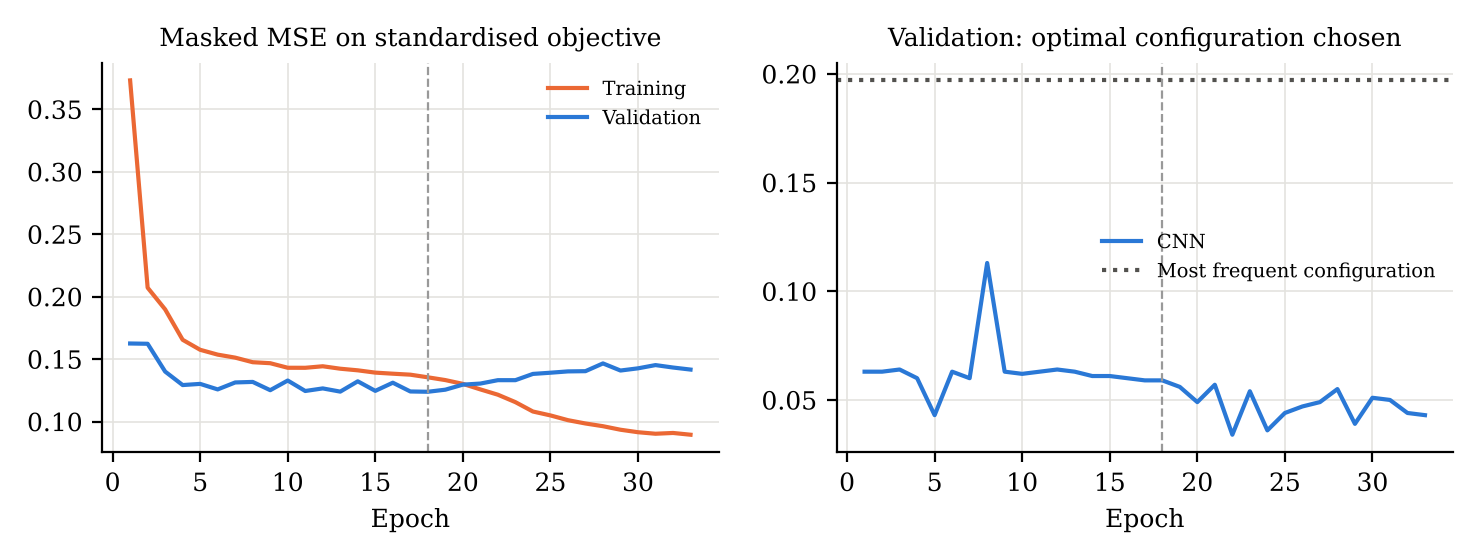

In [ ]:
table("table_cnn_validation")
figure("fig_training_curves")

### 5.3 System-level performance (20 paired runs)

**System-level performance over 20 independent paired runs (mean ± SD)**

| Scheme                 | PDR (%)      | End-to-end delay (s)   | Energy per node (J)   | Throughput (kbps)   | Weighted objective (rel. to RSSI)   |
|:-----------------------|:-------------|:-----------------------|:----------------------|:--------------------|:------------------------------------|
| Conventional LoRaWAN   | 73.66 ± 4.25 | 13.64 ± 5.17           | 1.029 ± 0.049         | 0.125 ± 0.030       | -0.142 ± 0.037                      |
| RSSI-based routing     | 77.28 ± 4.41 | 13.12 ± 4.59           | 1.014 ± 0.050         | 0.131 ± 0.032       | -0.108 ± 0.022                      |
| LEACH clustering       | 62.71 ± 6.01 | 308.48 ± 75.36         | 0.653 ± 0.102         | 0.106 ± 0.026       | -5.168 ± 2.474                      |
| Relay-assisted routing | 88.09 ± 2.62 | 11.57 ± 11.03          | 0.553 ± 0.048         | 0.151 ± 0.040       | 0.117 ± 0.128                       |
| Proposed CNN           | 87.69 ± 3.15 | 11.16 ± 11.03          | 0.560 ± 0.053         | 0.150 ± 0.039       | 0.114 ± 0.132                       |
| Exhaustive (labeller)  | 86.96 ± 3.57 | 5.66 ± 4.16            | 0.593 ± 0.057         | 0.149 ± 0.038       | 0.173 ± 0.058                       |


**95% confidence intervals (t-distribution, n = 20)**

| Scheme                 | PDR (%)        | End-to-end delay (s)   | Energy per node (J)   | Throughput (kbps)   | Weighted objective (rel. to RSSI)   |
|:-----------------------|:---------------|:-----------------------|:----------------------|:--------------------|:------------------------------------|
| Conventional LoRaWAN   | [71.67, 75.64] | [11.22, 16.06]         | [1.006, 1.052]        | [0.111, 0.139]      | [-0.159, -0.124]                    |
| RSSI-based routing     | [75.22, 79.35] | [10.97, 15.27]         | [0.991, 1.038]        | [0.116, 0.146]      | [-0.118, -0.098]                    |
| LEACH clustering       | [59.90, 65.53] | [273.22, 343.75]       | [0.606, 0.701]        | [0.094, 0.118]      | [-6.326, -4.010]                    |
| Relay-assisted routing | [86.87, 89.32] | [6.40, 16.73]          | [0.530, 0.575]        | [0.132, 0.170]      | [0.057, 0.177]                      |
| Proposed CNN           | [86.22, 89.17] | [6.00, 16.33]          | [0.536, 0.585]        | [0.132, 0.168]      | [0.052, 0.176]                      |
| Exhaustive (labeller)  | [85.29, 88.63] | [3.71, 7.60]           | [0.566, 0.619]        | [0.131, 0.167]      | [0.146, 0.200]                      |


**Relative change of the proposed CNN with respect to each scheme**

| Baseline               | PDR (%)   | End-to-end delay (s)   | Energy per node (J)   | Throughput (kbps)   |
|:-----------------------|:----------|:-----------------------|:----------------------|:--------------------|
| Conventional LoRaWAN   | +19.1%    | -18.1%                 | -45.6%                | +19.8%              |
| RSSI-based routing     | +13.5%    | -14.9%                 | -44.8%                | +14.2%              |
| LEACH clustering       | +39.8%    | -96.4%                 | -14.3%                | +41.4%              |
| Relay-assisted routing | -0.5%     | -3.5%                  | +1.4%                 | -0.6%               |
| Exhaustive (labeller)  | +0.8%     | +97.3%                 | -5.4%                 | +0.9%               |


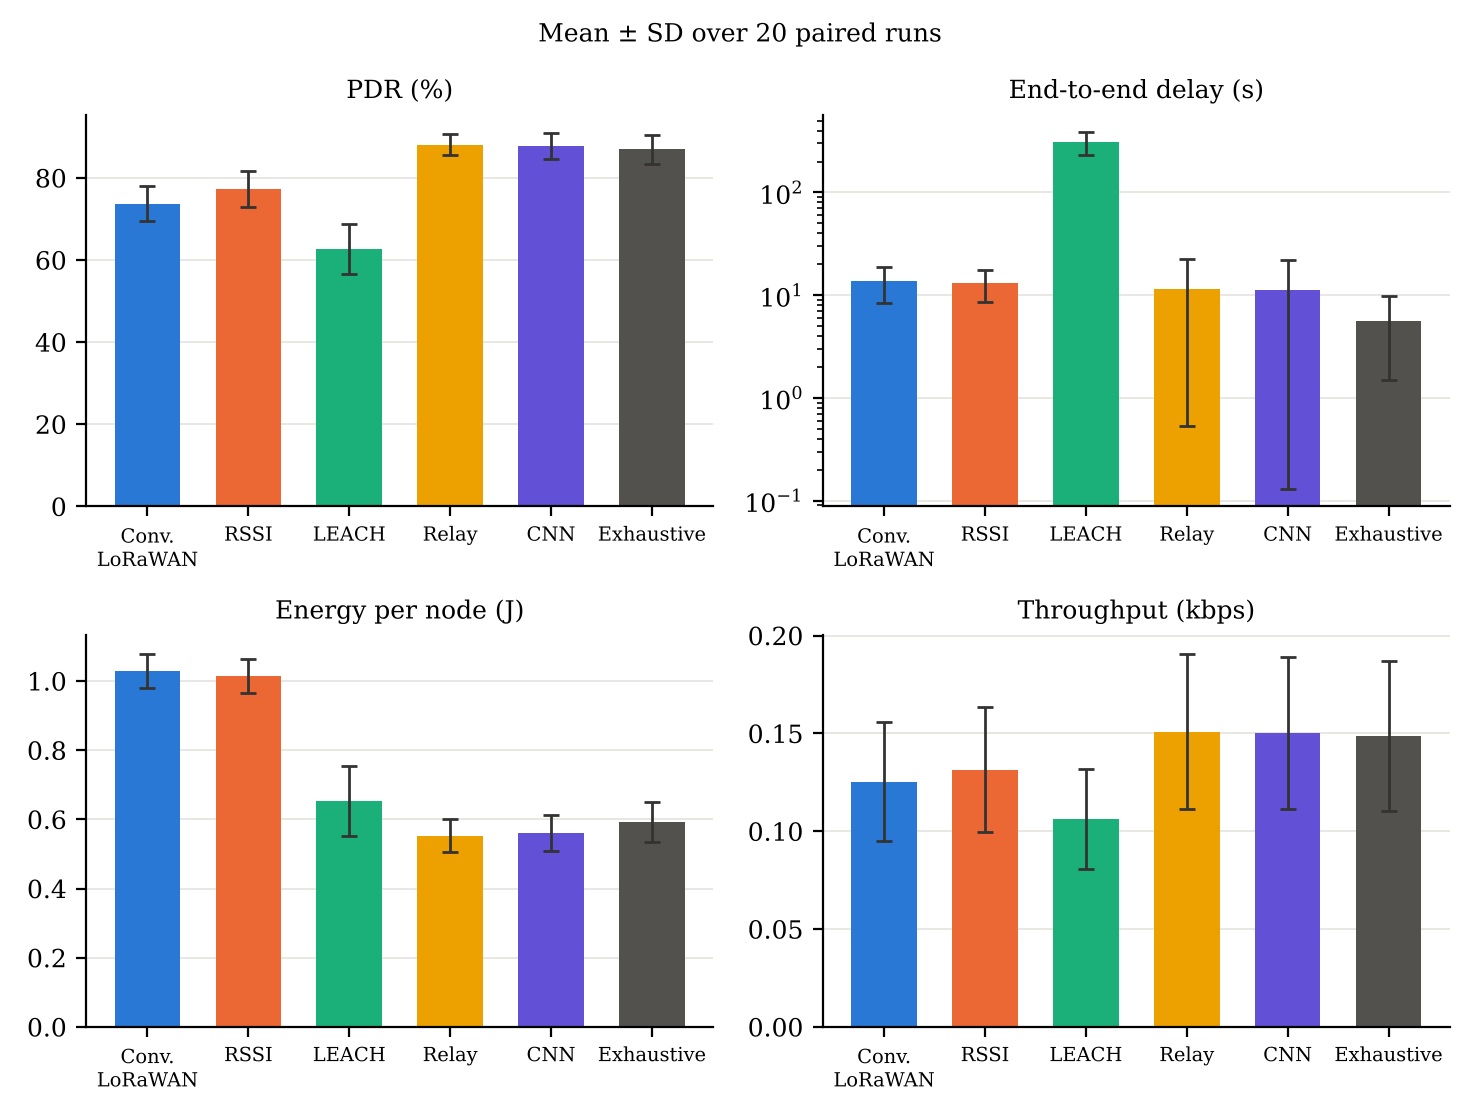

In [ ]:
table("table_main_results")
table("table_main_results_ci95")
table("table_relative_change")
figure("fig_main_results")

### 5.4 Paired t-tests with Holm–Bonferroni correction

In [ ]:
table("table_paired_tests")

**Paired t-tests (two-sided) with Holm-Bonferroni correction; Wilcoxon signed-rank as a check**

| Comparison                    | Metric                            |   mean_diff |       t |        p |   p_wilcoxon |   cohen_dz |   p_holm | significant (Holm, 0.05)   |
|:------------------------------|:----------------------------------|------------:|--------:|---------:|-------------:|-----------:|---------:|:---------------------------|
| CNN vs Conventional LoRaWAN   | PDR (%)                           |      14.038 |  31.664 | 6.62e-18 |     1.91e-06 |      7.08  | 1.52e-16 | yes                        |
| CNN vs Conventional LoRaWAN   | End-to-end delay (s)              |      -2.473 |  -1.103 | 0.284    |     0.0696   |     -0.247 | 1        | no                         |
| CNN vs Conventional LoRaWAN   | Energy per node (J)               |      -0.469 | -33.064 | 2.95e-18 |     1.91e-06 |     -7.393 | 7.37e-17 | yes                        |
| CNN vs Conventional LoRaWAN   | Throughput (kbps)                 |       0.025 |  12.769 | 9.01e-11 |     1.91e-06 |      2.855 | 1.71e-09 | yes                        |
| CNN vs Conventional LoRaWAN   | Weighted objective (rel. to RSSI) |       0.256 |   8.944 | 3.08e-08 |     9.54e-06 |      2     | 4.62e-07 | yes                        |
| CNN vs RSSI-based routing     | PDR (%)                           |      10.41  |  21.689 | 7.26e-15 |     1.91e-06 |      4.85  | 1.52e-13 | yes                        |
| CNN vs RSSI-based routing     | End-to-end delay (s)              |      -1.961 |  -0.891 | 0.384    |     0.177    |     -0.199 | 1        | no                         |
| CNN vs RSSI-based routing     | Energy per node (J)               |      -0.454 | -32.108 | 5.1e-18  |     1.91e-06 |     -7.18  | 1.22e-16 | yes                        |
| CNN vs RSSI-based routing     | Throughput (kbps)                 |       0.019 |  11.521 | 5.14e-10 |     1.91e-06 |      2.576 | 8.74e-09 | yes                        |
| CNN vs RSSI-based routing     | Weighted objective (rel. to RSSI) |       0.222 |   7.926 | 1.92e-07 |     9.54e-06 |      1.772 | 2.69e-06 | yes                        |
| CNN vs LEACH clustering       | PDR (%)                           |      24.981 |  25.719 | 3.15e-16 |     1.91e-06 |      5.751 | 6.94e-15 | yes                        |
| CNN vs LEACH clustering       | End-to-end delay (s)              |    -297.322 | -18.625 | 1.16e-13 |     1.91e-06 |     -4.165 | 2.32e-12 | yes                        |
| CNN vs LEACH clustering       | Energy per node (J)               |      -0.093 |  -5.201 | 5.08e-05 |     0.00021  |     -1.163 | 0.00066  | yes                        |
| CNN vs LEACH clustering       | Throughput (kbps)                 |       0.044 |  12.408 | 1.47e-10 |     1.91e-06 |      2.775 | 2.65e-09 | yes                        |
| CNN vs LEACH clustering       | Weighted objective (rel. to RSSI) |       5.282 |   9.561 | 1.08e-08 |     1.91e-06 |      2.138 | 1.73e-07 | yes                        |
| CNN vs Relay-assisted routing | PDR (%)                           |      -0.398 |  -1.711 | 0.103    |     0.0843   |     -0.383 | 0.724    | no                         |
| CNN vs Relay-assisted routing | End-to-end delay (s)              |      -0.403 |  -0.494 | 0.627    |     0.14     |     -0.11  | 1        | no                         |
| CNN vs Relay-assisted routing | Energy per node (J)               |       0.008 |   1.022 | 0.32     |     0.11     |      0.228 | 1        | no                         |
| CNN vs Relay-assisted routing | Throughput (kbps)                 |      -0.001 |  -1.612 | 0.123    |     0.0736   |     -0.36  | 0.741    | no                         |
| CNN vs Relay-assisted routing | Weighted objective (rel. to RSSI) |      -0.003 |  -0.533 | 0.6      |     0.14     |     -0.119 | 1        | no                         |
| CNN vs Exhaustive (labeller)  | PDR (%)                           |       0.732 |   2.404 | 0.0266   |     0.0736   |      0.538 | 0.292    | no                         |
| CNN vs Exhaustive (labeller)  | End-to-end delay (s)              |       5.505 |   2.301 | 0.0329   |     0.00451  |      0.515 | 0.32     | no                         |
| CNN vs Exhaustive (labeller)  | Energy per node (J)               |      -0.032 |  -2.799 | 0.0115   |     0.0414   |     -0.626 | 0.137    | no                         |
| CNN vs Exhaustive (labeller)  | Throughput (kbps)                 |       0.001 |   2.314 | 0.032    |     0.0596   |      0.517 | 0.32     | no                         |
| CNN vs Exhaustive (labeller)  | Weighted objective (rel. to RSSI) |      -0.059 |  -2.277 | 0.0345   |     0.0199   |     -0.509 | 0.32     | no                         |


### 5.5 Decision runtime

In [ ]:
table("table_runtime")

**Decision runtime per update over 100 states (single thread; x86_64)**

| Method                                | Runtime per update (ms)   |
|:--------------------------------------|:--------------------------|
| Exhaustive search (offline reference) | 192.26 ± 52.30            |
| DQN-based (one online step)           | 54.48 ± 13.56             |
| Greedy heuristic (max-RSSI)           | 8.33 ± 3.61               |
| Proposed CNN (tensor + inference)     | 2.34 ± 0.73               |


### 5.6 Network density

**Mean PDR (%) versus network density**

|   Nodes |   Conventional LoRaWAN |   RSSI-based routing |   LEACH clustering |   Relay-assisted routing |   Proposed CNN |   Exhaustive (labeller) |
|--------:|-----------------------:|---------------------:|-------------------:|-------------------------:|---------------:|------------------------:|
|     200 |                  84.61 |                89.47 |              79.83 |                    93.85 |          93.76 |                   93.85 |
|     300 |                  81.1  |                85.11 |              73.58 |                    92.62 |          92.33 |                   92.62 |
|     400 |                  78.29 |                82.7  |              66.55 |                    90.55 |          90.37 |                   90.66 |
|     500 |                  75.11 |                79.06 |              62.76 |                    88.61 |          88.39 |                   88.58 |
|     600 |                  72.5  |                76.14 |              59.58 |                    87.26 |          86.89 |                   86.07 |
|     700 |                  69.59 |                73.06 |              57.69 |                    85.68 |          85.26 |                   83.31 |
|     800 |                  67.11 |                70.6  |              53.17 |                    84.45 |          81.24 |                   82.31 |


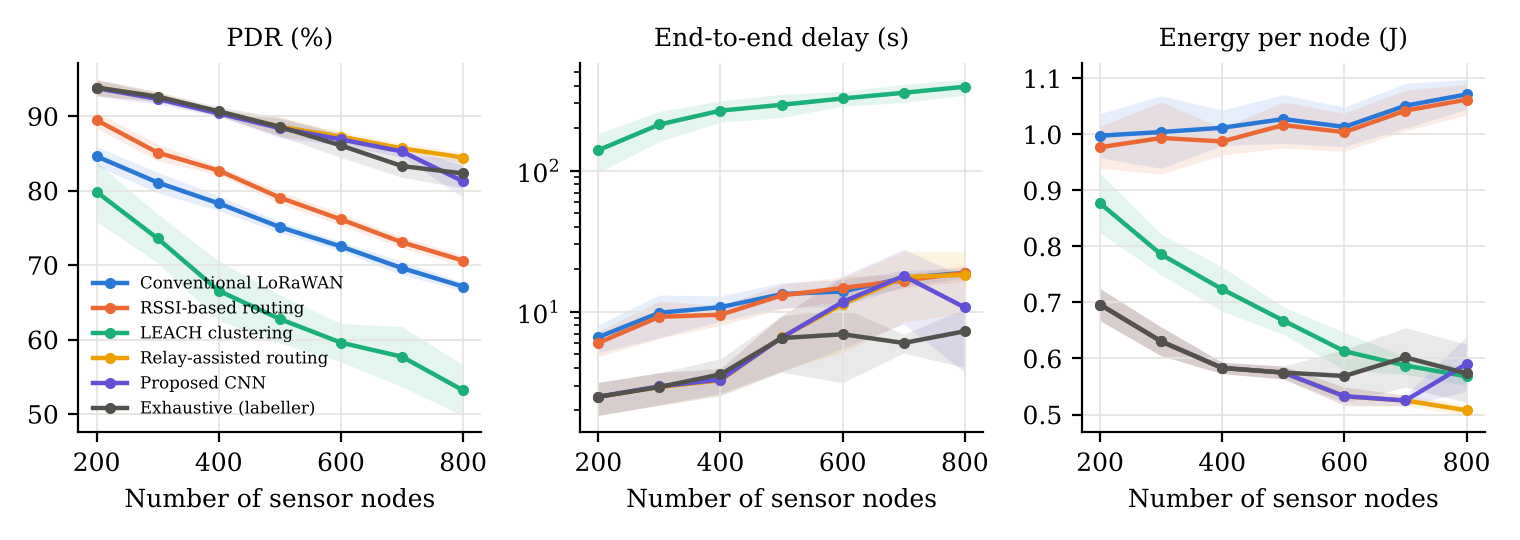

In [ ]:
table("table_density_pdr")
figure("fig_density")

### 5.7 Objective-weight sensitivity

**Effect of the reliability weight (means over runs, fixed node count)**

|   w1 | method     |    pdr |   energy_j |   delay_s |
|-----:|:-----------|-------:|-----------:|----------:|
|  0.3 | cnn        | 89.057 |      0.572 |     8.07  |
|  0.3 | exhaustive | 88.875 |      0.583 |     5.638 |
|  0.3 | relay      | 89.186 |      0.572 |     7.981 |
|  0.4 | cnn        | 89.057 |      0.572 |     8.07  |
|  0.4 | exhaustive | 88.875 |      0.583 |     5.638 |
|  0.4 | relay      | 89.186 |      0.572 |     7.981 |
|  0.5 | cnn        | 89.057 |      0.572 |     8.07  |
|  0.5 | exhaustive | 88.55  |      0.595 |     4.59  |
|  0.5 | relay      | 89.186 |      0.572 |     7.981 |
|  0.6 | cnn        | 89.057 |      0.572 |     8.07  |
|  0.6 | exhaustive | 88.55  |      0.595 |     4.59  |
|  0.6 | relay      | 89.186 |      0.572 |     7.981 |
|  0.7 | cnn        | 89.057 |      0.572 |     8.07  |
|  0.7 | exhaustive | 88.55  |      0.595 |     4.59  |
|  0.7 | relay      | 89.186 |      0.572 |     7.981 |
|  0.8 | cnn        | 89.057 |      0.572 |     8.07  |
|  0.8 | exhaustive | 88.55  |      0.595 |     4.59  |
|  0.8 | relay      | 89.186 |      0.572 |     7.981 |
|  0.9 | cnn        | 89.057 |      0.572 |     8.07  |
|  0.9 | exhaustive | 88.55  |      0.595 |     4.59  |
|  0.9 | relay      | 89.186 |      0.572 |     7.981 |


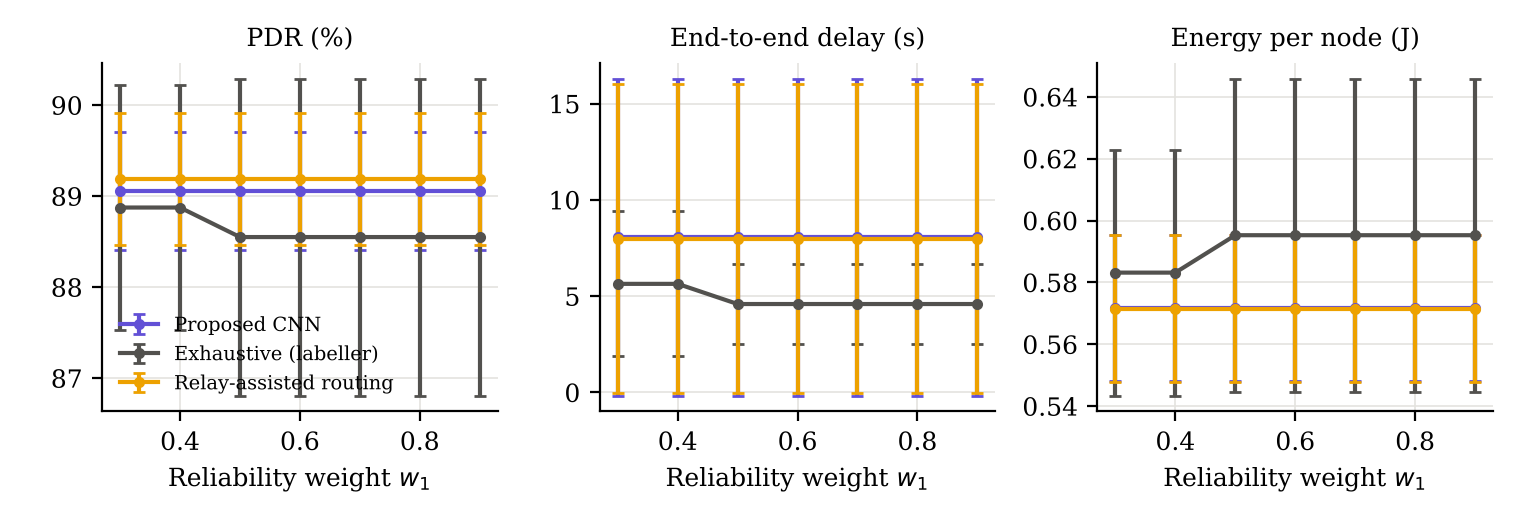

In [ ]:
table("table_sensitivity_weights")
figure("fig_sensitivity_weights")

### 5.8 Input-channel ablation

In [ ]:
table("table_ablation")

**Leave-one-channel-out ablation (validation metrics and simulated network metrics)**

| variant                  |   score_correlation |   mean_normalised_regret |   val_top1 |     pdr |   energy_j |   delay_s |
|:-------------------------|--------------------:|-------------------------:|-----------:|--------:|-----------:|----------:|
| full                     |              0.9362 |                   0.0496 |      0.059 | 86.5331 |     0.5879 |   20.8065 |
| without_rssi             |              0.9362 |                   0.049  |      0.063 | 86.8886 |     0.5746 |   25.2709 |
| without_energy           |              0.9362 |                   0.0498 |      0.047 | 87.1902 |     0.5745 |   25.2934 |
| without_density          |              0.9361 |                   0.049  |      0.062 | 86.8886 |     0.5746 |   25.2709 |
| without_traffic_mobility |              0.9363 |                   0.0486 |      0.061 | 86.1186 |     0.6017 |   19.768  |
| without_fill             |              0.9365 |                   0.049  |      0.062 | 86.8886 |     0.5746 |   25.2709 |


## 6. Notes for readers
* Seeds are derived from `seed` in the configuration with `numpy.random.SeedSequence`, with separate streams for dataset, training, evaluation, runtime, density, sensitivity, ablation and labeller check, so evaluation scenarios never overlap training scenarios.
* All methods in an evaluation run share the same scenario and packet-level random stream, so comparisons are paired.
* Runtime values depend on hardware; relative ordering is the meaningful quantity.
* Modelling choices not fixed by the manuscript (candidate set, grid size, fill-level weighting, objective normalisation, sink encoding, baseline definitions, delay definition) are each a single setting in the configuration or one function in `lorasw/`.